# 08b — Model evaluation: where the candidate went wrong

This notebook is deliberately separate from the runnable submission pipeline. It loads the candidate produced by `08_run_pipeline.ipynb`, joins the supplied public labels only for evaluation, ranks contiguous disagreement intervals, and renders the observations around every disagreement.

The public labels are never fed back into feature construction or prediction. The plots are an error-analysis aid for deciding which observation or transition hypothesis needs improvement. The runnable pipeline also emits `diagnostic_no_switch_restart_phase_interval.csv`, which applies restart observations as phase evidence and transition constraints before the shared interval resolver; this notebook can compare that structural candidate with the active output without treating the public slice as training data. The final audit section also renders the George + Kalman path-fusion interaction/attempted-pass experiment separately, so any changed frames and disagreement windows remain visible without promoting them into the submitted model.

## Metric summary

The notebook computes the current values from the candidate and the public five-minute slice; use the measures together rather than treating one score as the whole result.

| Measure | What it tells us |
|---|---|
| Macro-F1 | Balanced per-frame quality across H, A, and D. |
| Mean Spell-F1 | Whether possession spells have the right boundaries and continuity. |
| Transition F1 (±25 frames) | Whether possession changes occur near the reference transition. |
| Disagreement intervals | Which contiguous errors need evidence-level review. |

These are retrospective diagnostics on the public slice, not training labels or a guarantee of private-match performance.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'possession_lab').exists() and (ROOT.parent / 'possession_lab').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA_ROOT = ROOT / 'data'
BEST_OUTPUT = ROOT / 'evaluation' / 'results' / 'diagnostic_forward_settling_dead_ball.csv'
GROUND_TRUTH = ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv'
if not BEST_OUTPUT.exists():
    raise FileNotFoundError(f'Run 08_run_pipeline.ipynb first; candidate is missing: {BEST_OUTPUT}')
os.environ['MTAH_DATA_DIR'] = str(DATA_ROOT)
print(f'candidate: {BEST_OUTPUT}')
print(f'public labels: {GROUND_TRUTH}')

candidate: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/diagnostic_forward_settling_dead_ball.csv
public labels: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/gt/BAR-ATH_possession_gt_public.csv


## Disagreement intervals

A disagreement is an observed public frame where the candidate label differs from the public label. Adjacent disagreement frames are grouped into one interval so that a transition error is not counted as dozens of unrelated frame errors. The table is ranked by interval duration.

In [2]:
from possession_lab.calculations.features import build_engineered_features
from possession_lab.baseline_pipeline import ClosestTeamRuleModel
from possession_lab.temporal_rules import load_rules

# Rebuild observations for plotting only; the public labels enter after this table exists.
plot_features = build_engineered_features(model=ClosestTeamRuleModel(), rules=load_rules())
ground_truth = pd.read_csv(GROUND_TRUTH)
prediction = pd.read_csv(BEST_OUTPUT)
gt_by_frame = pd.Series(ground_truth['label'].astype(str).str.upper().to_numpy(), index=ground_truth['frame'].astype(int))
pred_by_frame = pd.Series(prediction['label'].astype(str).str.upper().to_numpy(), index=prediction['frame'].astype(int))
graded_mismatch = (gt_by_frame != 'X') & gt_by_frame.notna() & pred_by_frame.notna() & gt_by_frame.ne(pred_by_frame)
mismatch_frames = graded_mismatch[graded_mismatch].index.to_numpy(dtype=int)
if len(mismatch_frames) == 0:
    mismatch_windows = []
    window_table = pd.DataFrame(columns=['start_frame', 'end_frame', 'duration_frames', 'duration_s'])
    print('No public disagreement windows found.')
else:
    groups = np.split(mismatch_frames, np.where(np.diff(mismatch_frames) > 1)[0] + 1)
    mismatch_windows = sorted(((int(group[0]), int(group[-1])) for group in groups), key=lambda pair: pair[1] - pair[0], reverse=True)
    window_table = pd.DataFrame(mismatch_windows, columns=['start_frame', 'end_frame'])
    window_table['duration_frames'] = window_table['end_frame'] - window_table['start_frame'] + 1
    window_table['duration_s'] = window_table['duration_frames'] / 25.0
    display(window_table)
    print(f'public disagreement windows: {len(window_table)}; wrong graded frames: {len(mismatch_frames)}')

,start_frame,end_frame,duration_frames,duration_s
0,17293,17455,163,6.52
1,11351,11497,147,5.88
2,15656,15761,106,4.24
3,15908,15993,86,3.44
4,11553,11623,71,2.84
5,13785,13825,41,1.64
6,15766,15798,33,1.32
7,14846,14875,30,1.20
8,13680,13703,24,0.96
9,12831,12850,20,0.80


public disagreement windows: 18; wrong graded frames: 804


## Where the model went wrong

The loop below renders every disagreement window with context. The timeline compares candidate and public labels while retaining scenario and anchor observations. The final four-panel plot adds distance margin, nearest-player distance and closing effort, ball speed/acceleration, and kick-episode distance for the longest interval. Grey shading marks unavailable grading; orange shading marks missing-ball observations.

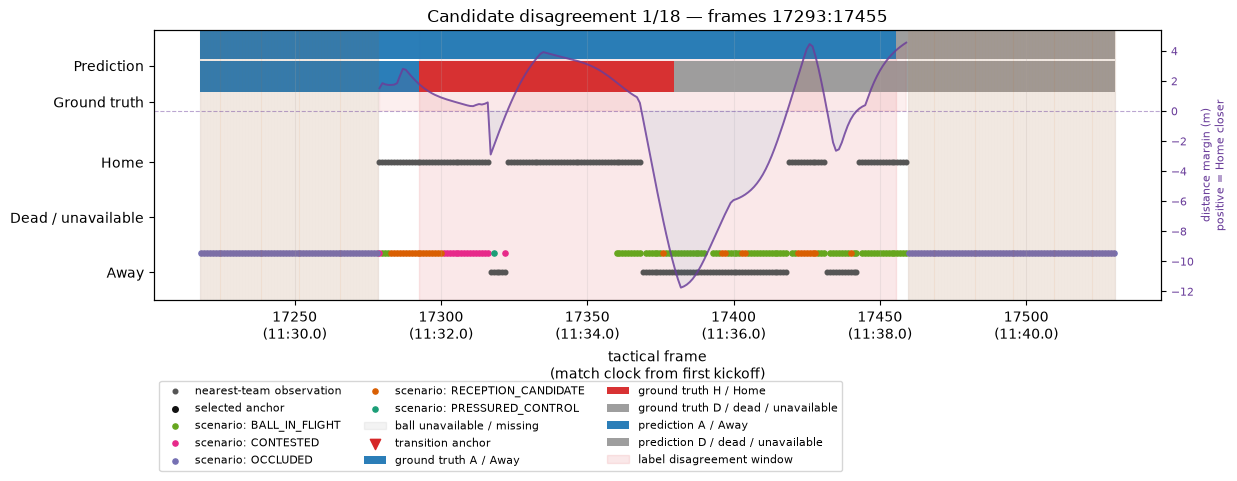

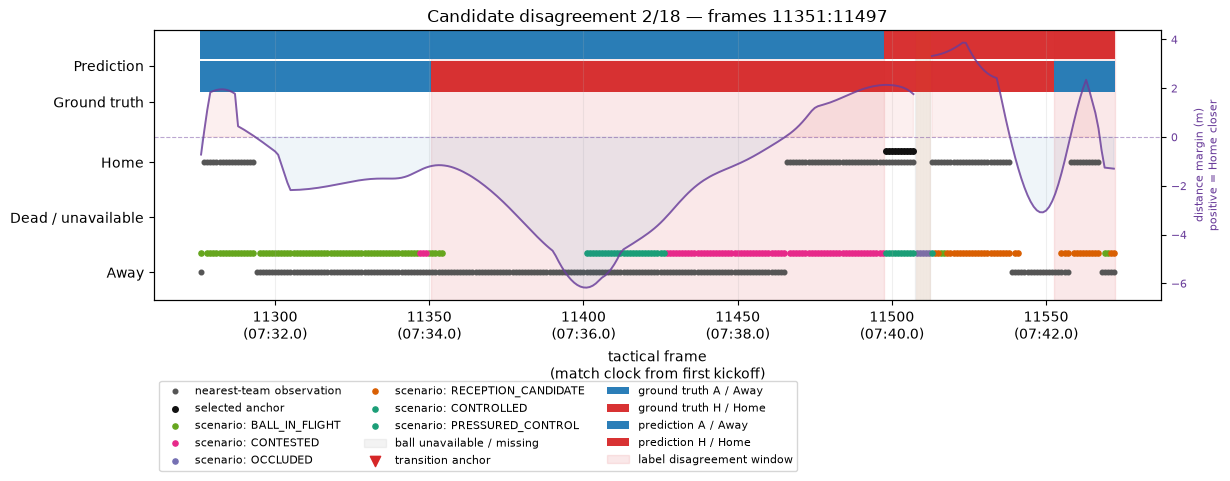

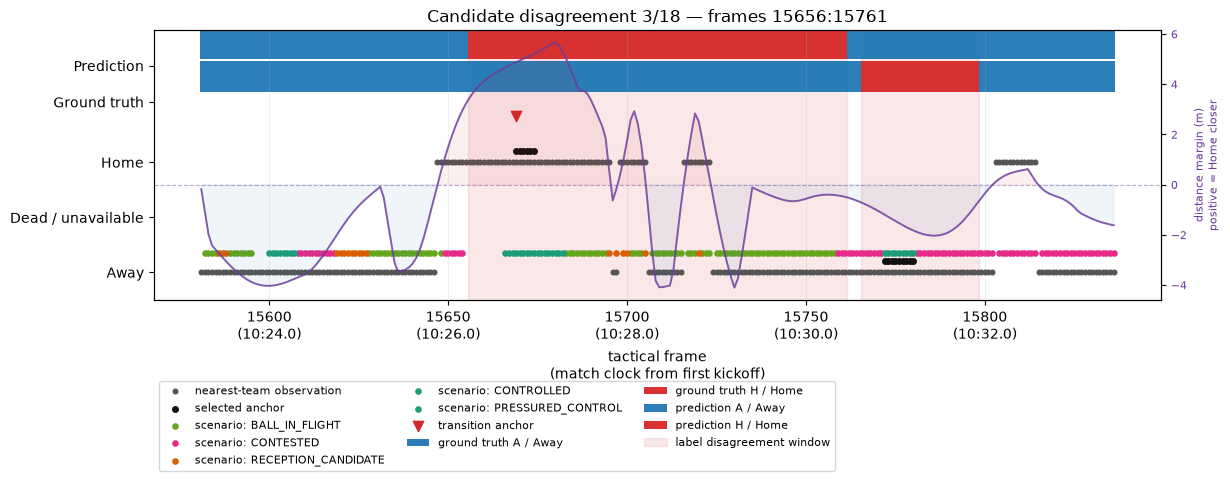

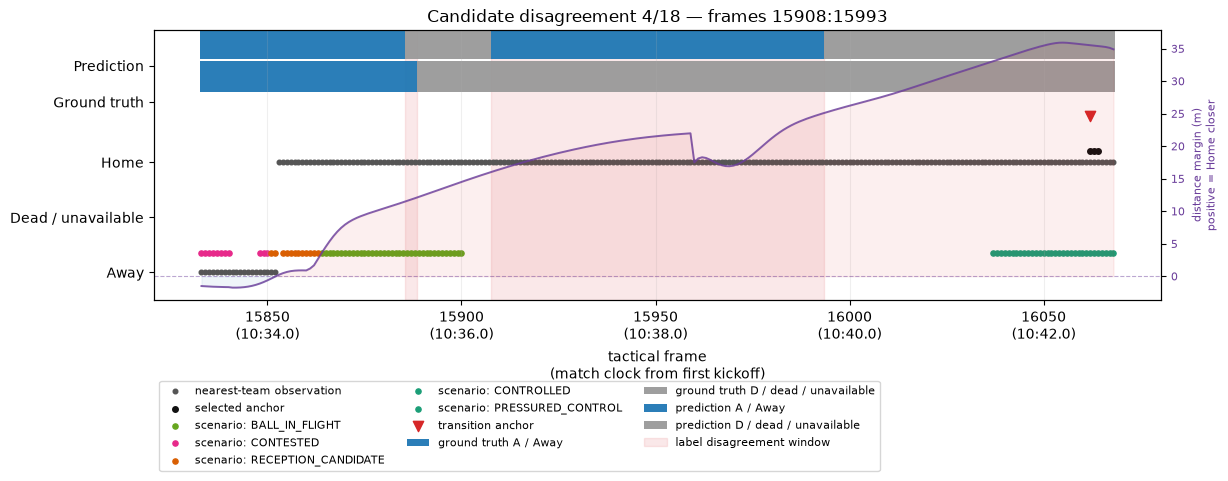

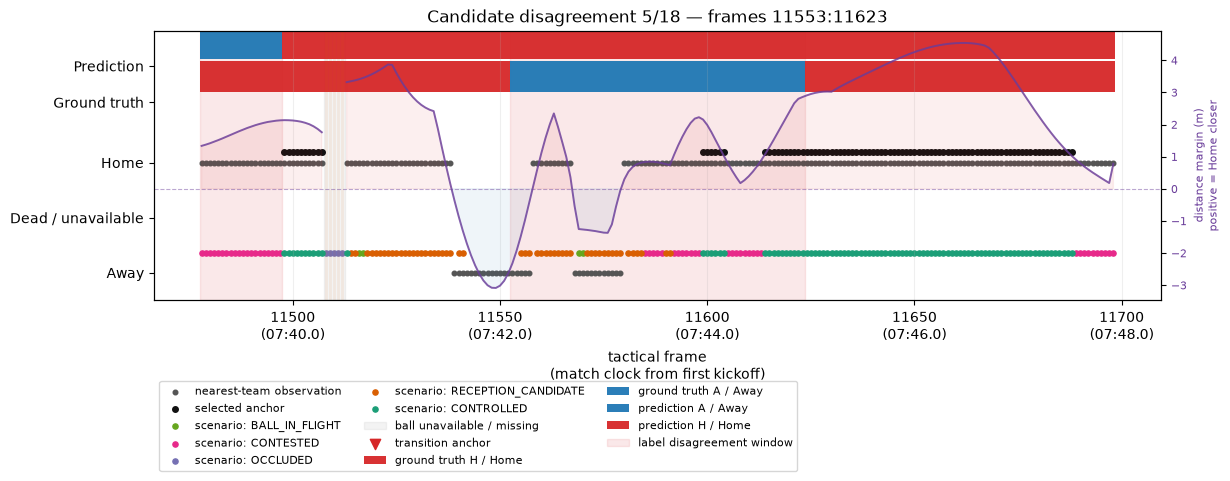

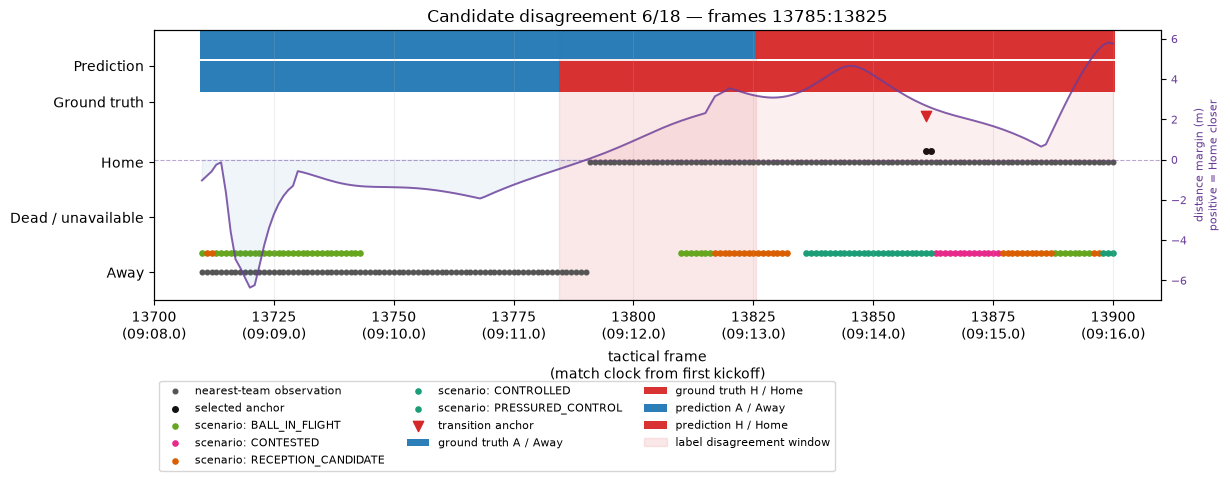

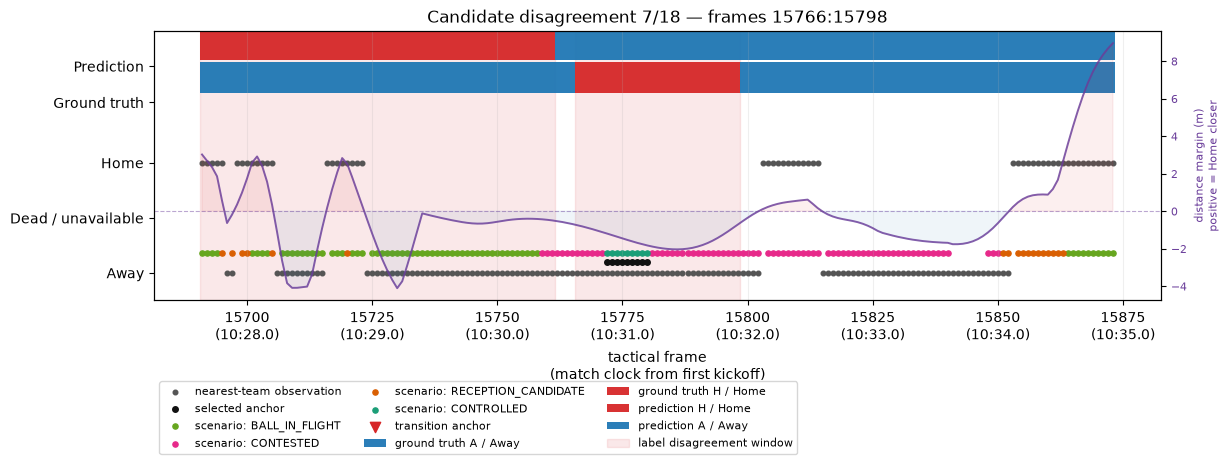

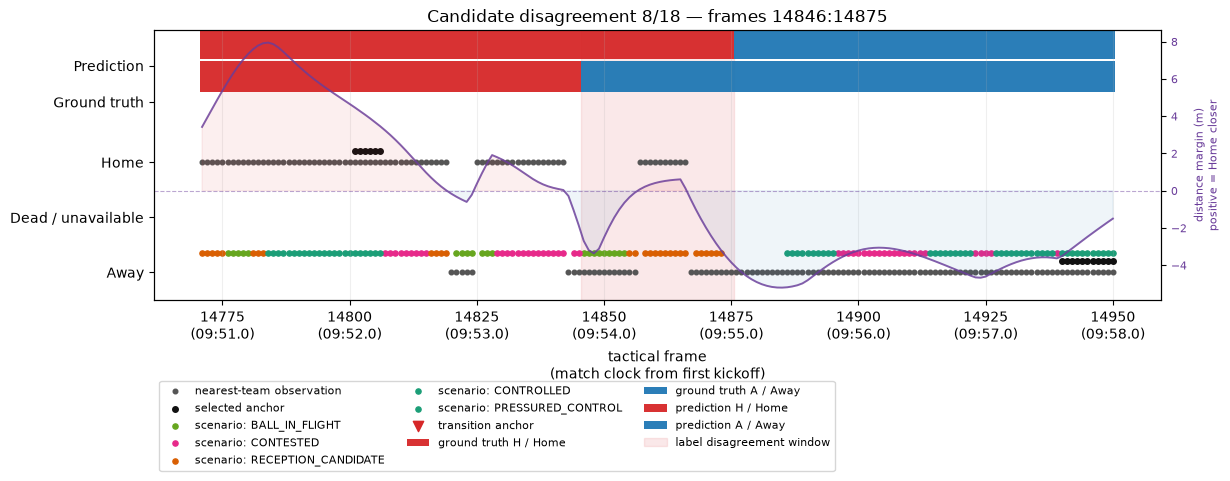

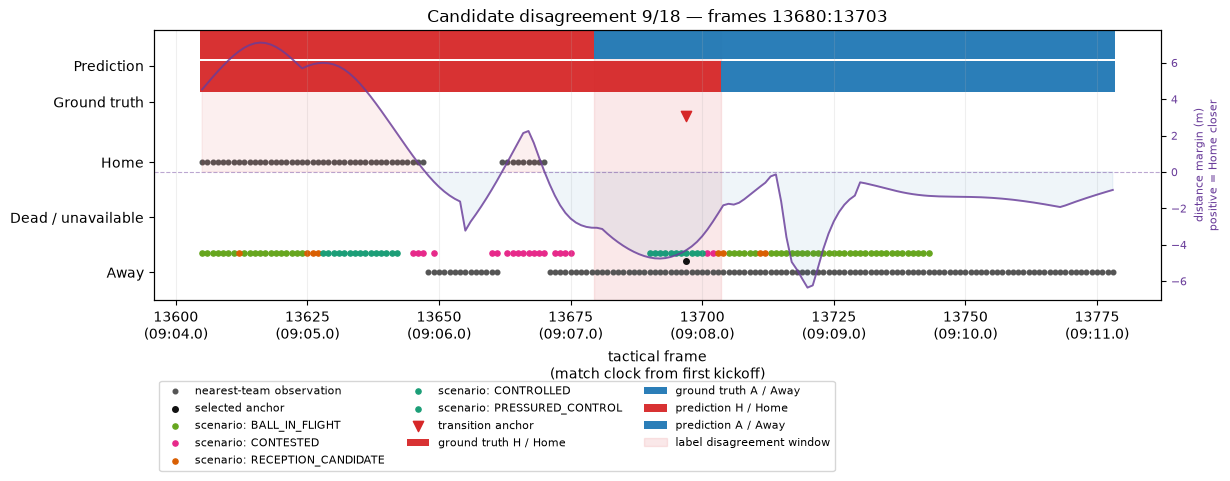

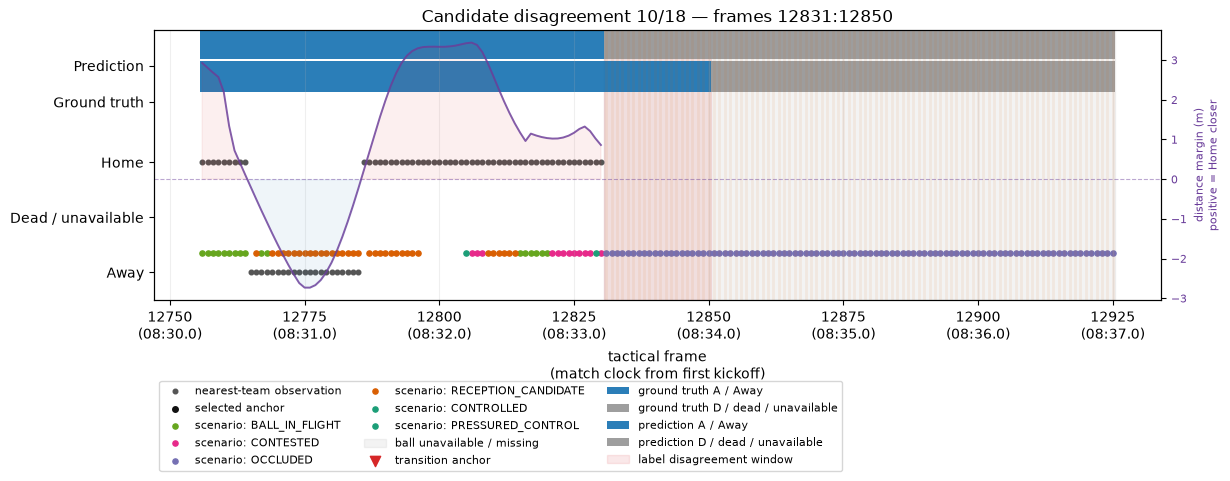

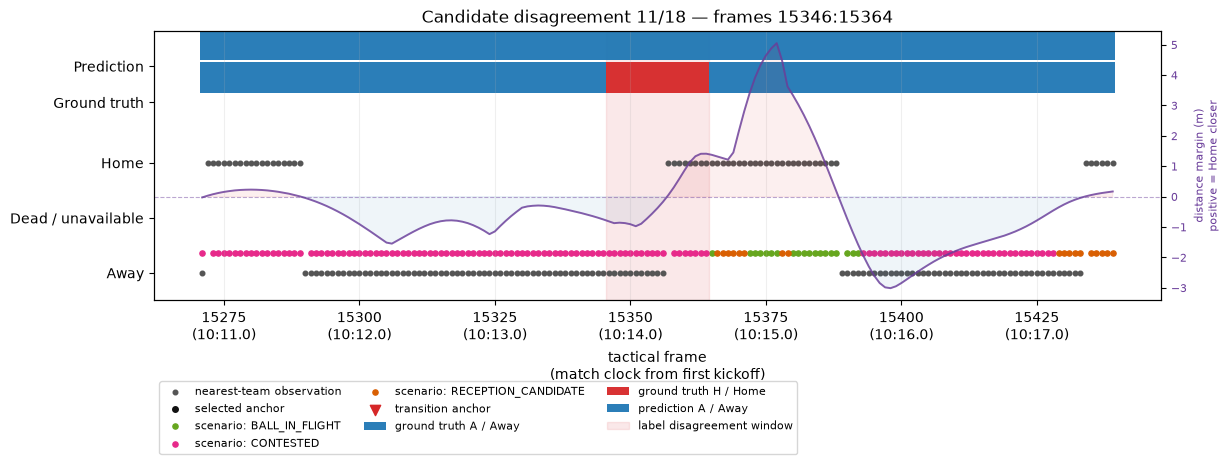

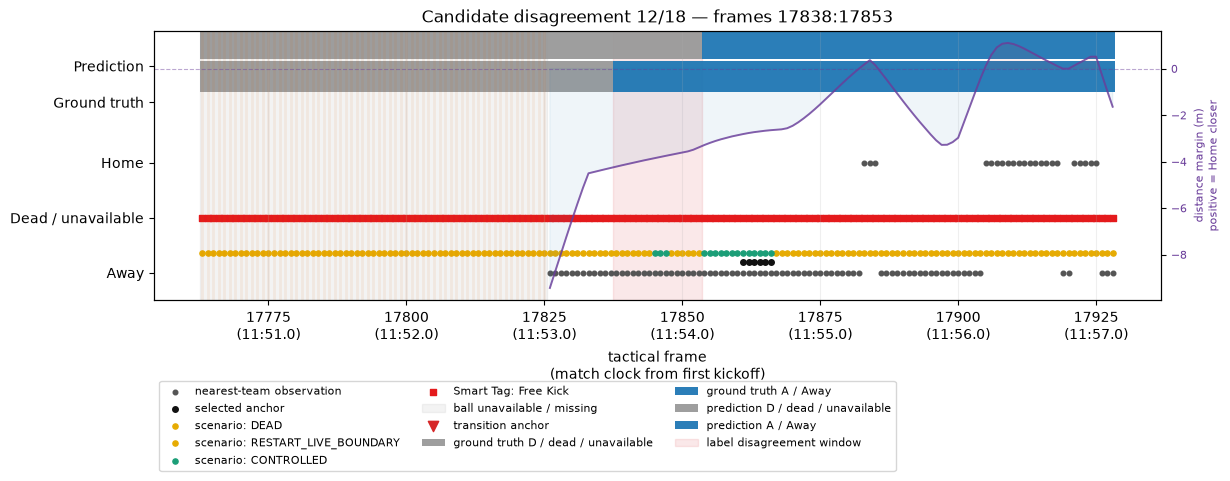

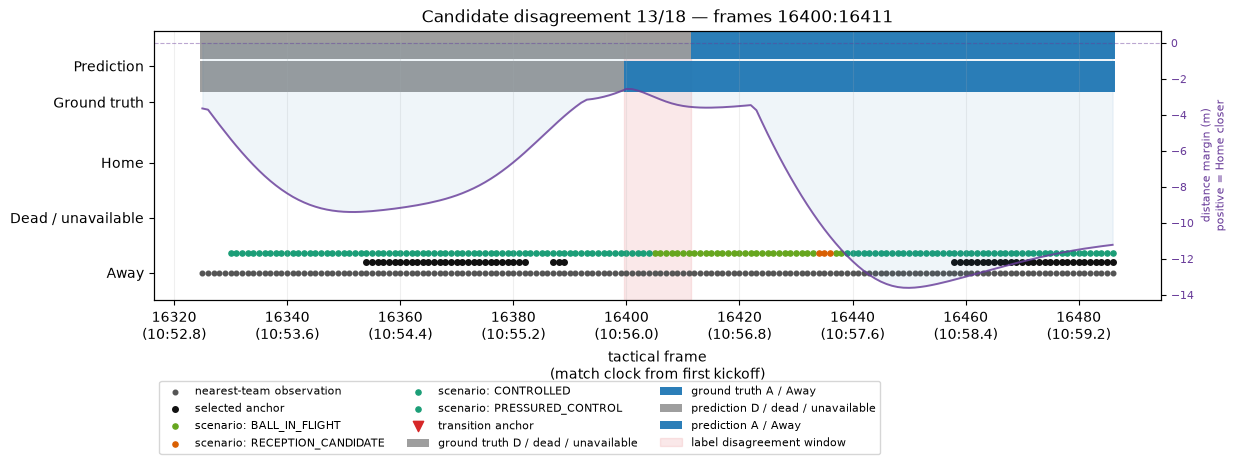

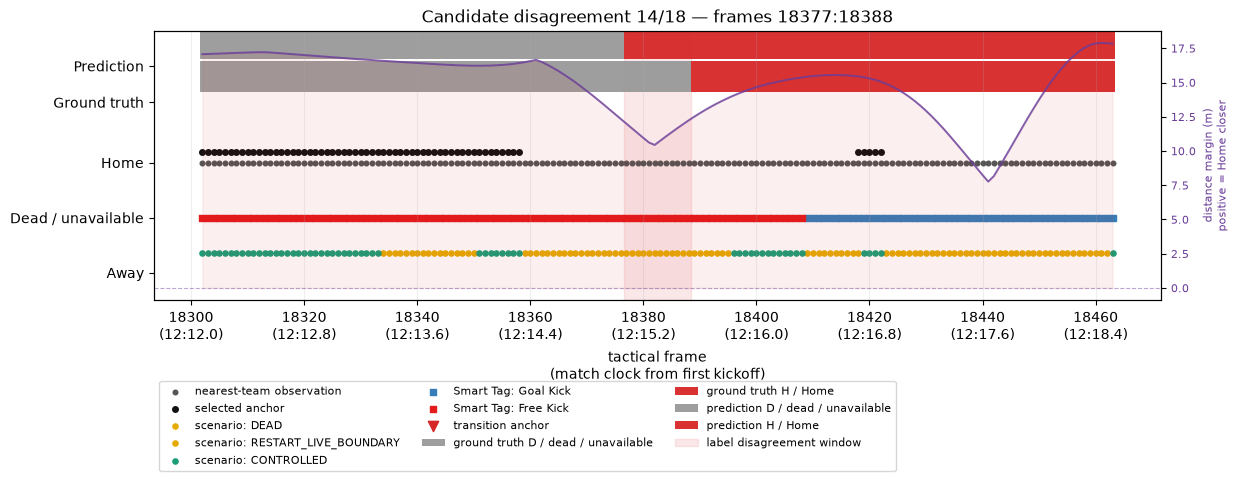

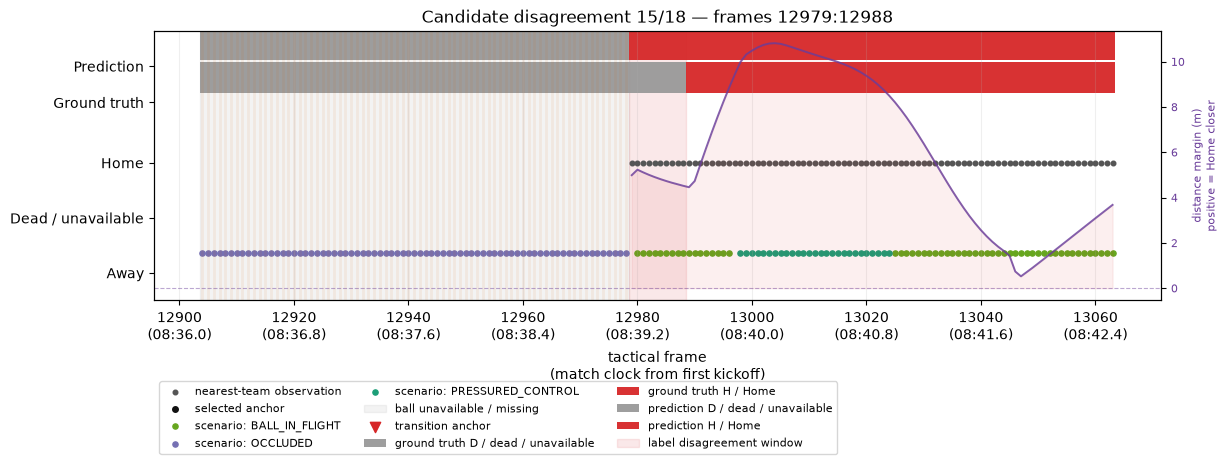

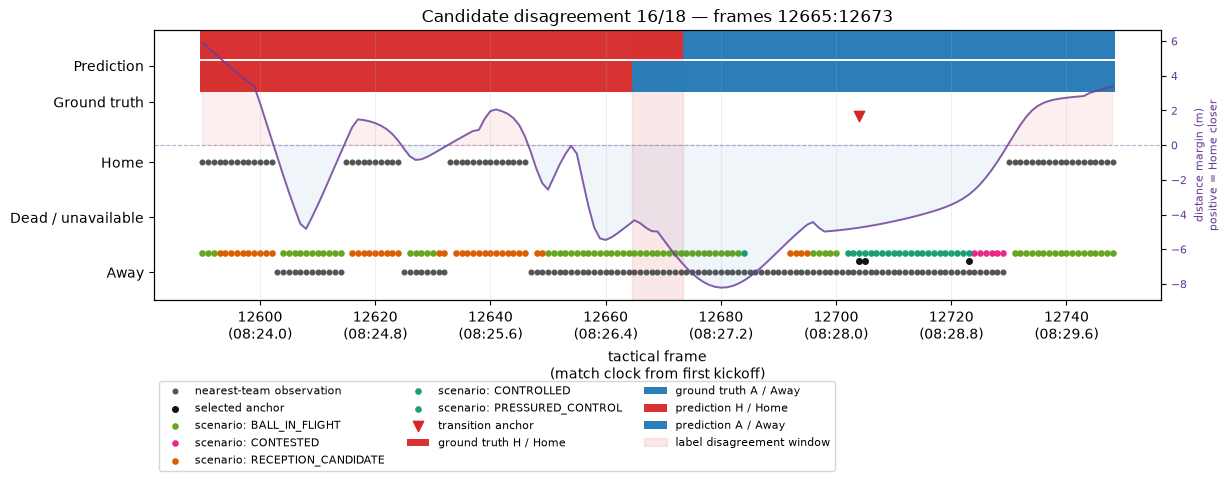

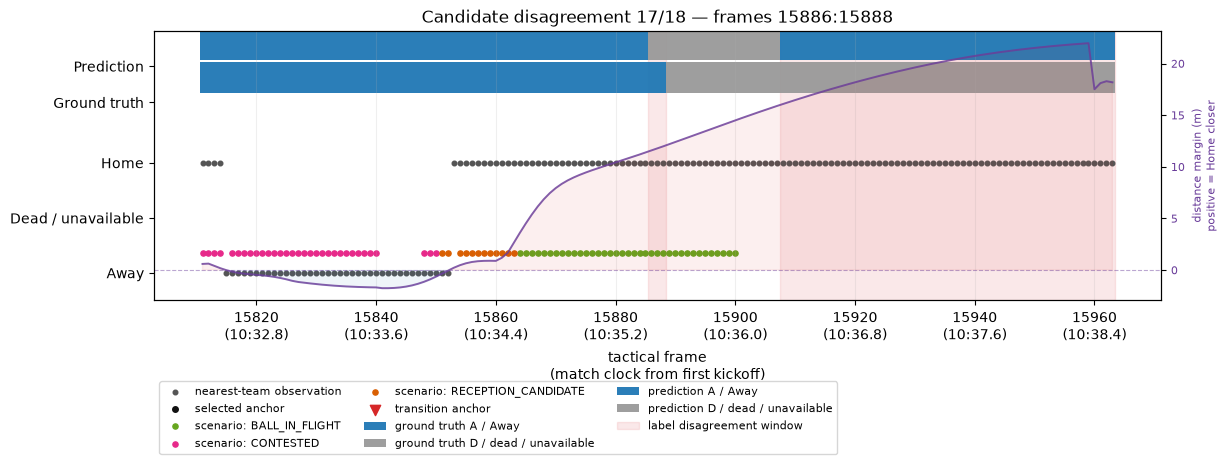

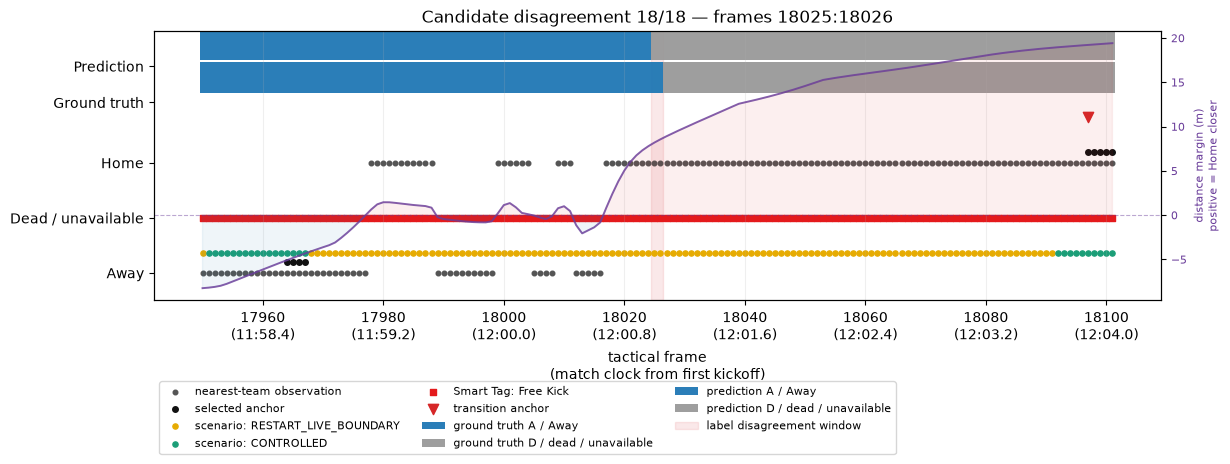

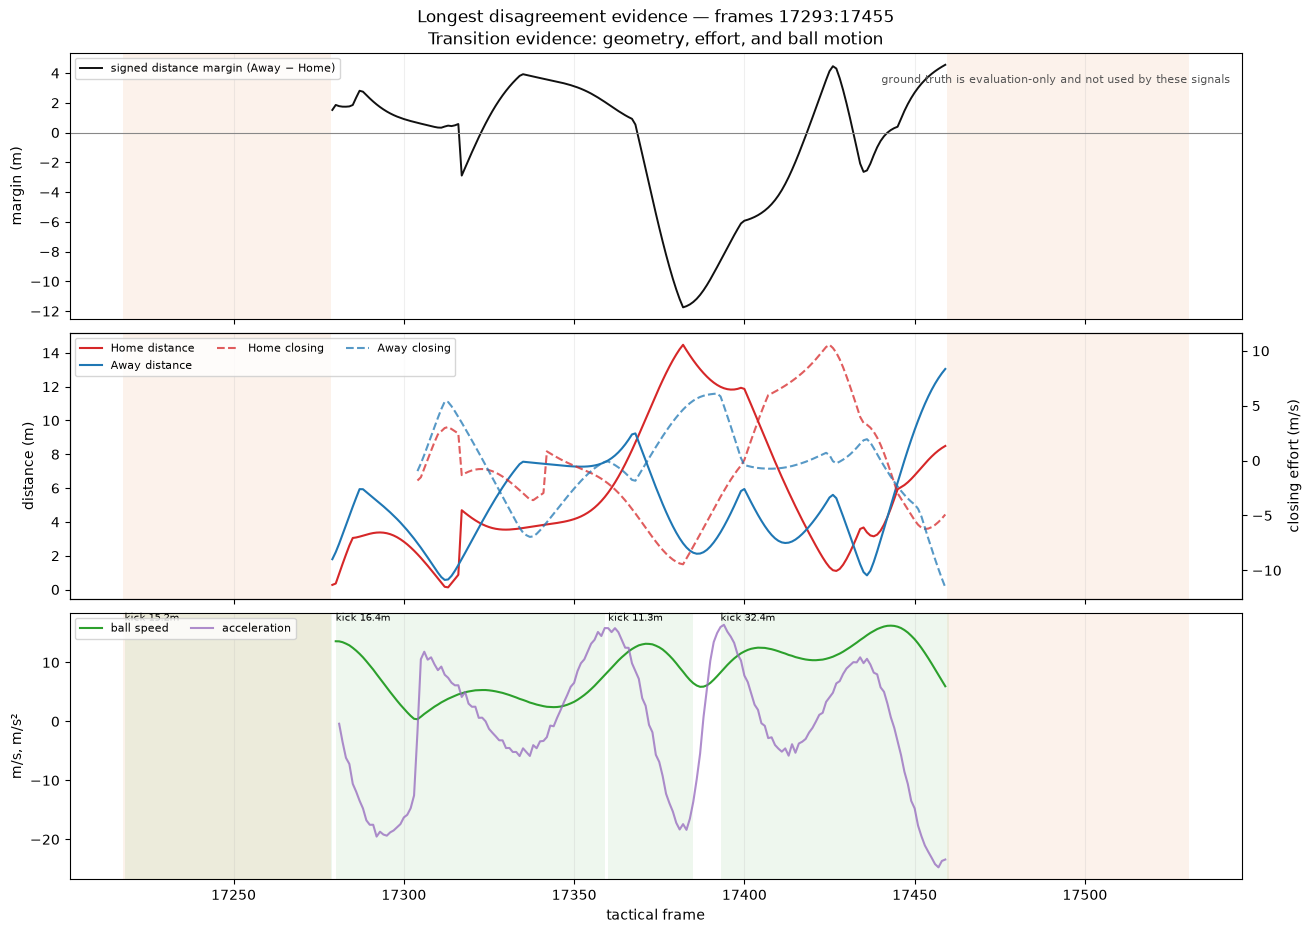

In [3]:
from possession.calculations.plotting import plot_timeline_window
from possession_lab.calculations.plotting import plot_transition_signals_window

context_frames = 75
for number, (window_start, window_end) in enumerate(mismatch_windows, start=1):
    left = max(int(plot_features['frame'].min()), window_start - context_frames)
    right = min(int(plot_features['frame'].max()), window_end + context_frames)
    figure, axis = plot_timeline_window(plot_features, left, right, ground_truth=gt_by_frame, predicted_labels=pred_by_frame)
    axis.set_title(f'Candidate disagreement {number}/{len(mismatch_windows)} — frames {window_start}:{window_end}')
    plt.show()

if mismatch_windows:
    window_start, window_end = mismatch_windows[0]
    left = max(int(plot_features['frame'].min()), window_start - context_frames)
    right = min(int(plot_features['frame'].max()), window_end + context_frames)
    figure, axes = plot_transition_signals_window(plot_features, left, right, ground_truth=gt_by_frame)
    figure.suptitle(f'Longest disagreement evidence — frames {window_start}:{window_end}', y=1.02)
    plt.show()

## Interpretation

These plots are diagnostic, not training data. Read each interval as: observations → scenario evidence → transition/no-switch hypotheses → resolved label. The transition audit now separates CONTACT_ANCHOR (something happened), SWITCH_HYPOTHESIS (ownership question), CONTROL_ANCHOR (persistent team control), and RESTART_ACTIVATION (play is live again); a long-ball launch identifies the initiating team without claiming the landing. For restart windows, the intended chain is restart observations → restart phase/evidence → transition constraints → shared interval resolver → final H/A/D/X label. A disagreement is evidence that this chain needs review; it is not permission to overwrite the candidate using the public label.

## Disagreement signal audit: density and pressure

**Problem.** The model's remaining public disagreements could be caused by a missing signal rather than a wrong global threshold.

**Idea.** Compare observations on correct and incorrect graded frames, using the public labels only after the candidate has already been generated. The audit includes opponent density, pressure, closing speed, pass options, significant-player counts, crowd score, landing-area density, and missing-ball uncertainty.

**Result.** The current candidate has 820 graded errors out of 7,500 graded frames. Errors are concentrated in H↔A runs inside CONTESTED, UNKNOWN, and BALL_IN_FLIGHT, plus D→A runs near those boundaries. Error frames have higher local density and more significant players on average. This supports a transition-risk/uncertainty signal, not a direct team assignment: crowding is compatible with both pressured control and a turnover.

**Decision.** The density/pressure features remain in the evidence ledger and can lower switch trust or support CONTESTED. They are not promoted as a new hard scenario or as a rule that changes H/A by itself. The public labels are not used by the runnable pipeline.

## Disagreement overlap with missing-ball intervals

**Problem.** A disagreement during a missing-ball interval is not the same failure as a disagreement with a visible ball. We therefore measure the overlap explicitly before changing the resolver.

**Method.** The audit uses the original tactical coordinates (when George is attached, `ball_x_tactical`/`ball_y_tactical`) to mark the source gap. This prevents a filled coordinate from hiding the very missing-ball case we are trying to understand. Public labels are joined only after the candidate has been generated.

**Public result.** There are 885 graded frames with a source ball gap, but only 20 of the 820 graded disagreements occur there (2.44% of disagreements). Most remaining errors are visible-ball H/A or D-boundary errors. This supports keeping George as a selective/evidence-only robustness layer and improving contact/arrival evidence before making a global fill rule.

In [4]:
from possession_lab.mislabel_audit import build_missing_ball_disagreement_audit

missing_ball_audit = build_missing_ball_disagreement_audit(
    GROUND_TRUTH,
    BEST_OUTPUT,
    plot_features,
    ROOT / 'evaluation/reports/missing_ball_disagreement_summary.csv',
)
display(missing_ball_audit['summary'])
display(missing_ball_audit['by_error'])

,population,frames,disagreement_frames,disagreement_rate,fraction_of_all_disagreements
0,all_graded,7500,804,0.107200,1.000000
1,ball_visible_graded,6615,784,0.118519,0.975124
2,ball_missing_graded,885,20,0.022599,0.024876
3,george_observed_gap_graded,0,0,NaN,0.000000


,error_type,ball_missing_source_gap,frames
5,H_TO_A,False,351
2,A_TO_H,False,216
3,D_TO_A,False,162
0,A_TO_D,False,33
4,D_TO_H,False,22
1,A_TO_D,True,20


## George + Kalman interaction/attempted-pass audit

**Question.** Could a persistent interaction or attempted pass identify a small live-ball switch that the interval resolver leaves as `NO_SWITCH`?

**Experiment.** The candidate is allowed to restore only a proposed H/A handoff suppressed by `NO_SWITCH`. It requires a multi-frame interaction signal, contact/motion evidence, a later stable control anchor, and a selected George-direct/George-flight/low-uncertainty-Kalman path whenever the tactical ball is missing. This is a transition hypothesis test, not a public-label correction.

The public labels below are joined only for evaluation. If the experiment changes a false switch, it is evidence against the rule; if it changes a missed switch without increasing false switches, it is a candidate for further private-match validation. In the current public run, the 3/5/8-frame variants make no additional label changes and score 0.8894 / 0.6207 / 0.4000, below the promoted 0.8917 / 0.6207 / 0.4571 reference.

,submission,macro_f1,spell_f1_mean,trans_f1_25
22,diagnostic_visible_ball_no_switch_interval,0.891747,0.62069,0.457143
28,diagnostic_george_interaction_attempted_pass_min3,0.889438,0.62069,0.400000


promoted reference: 804 wrong graded frames; 18 disagreement windows


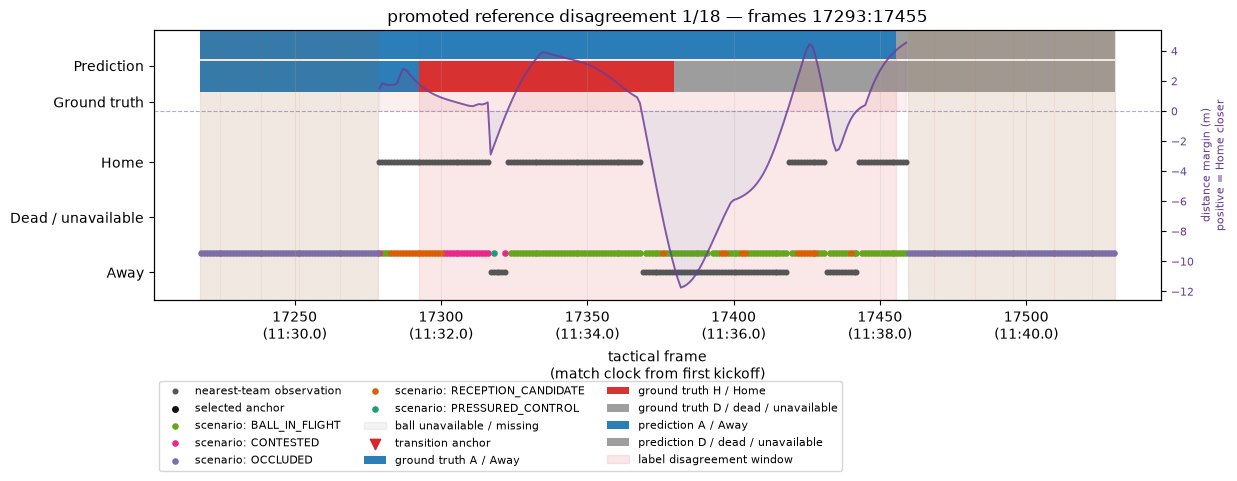

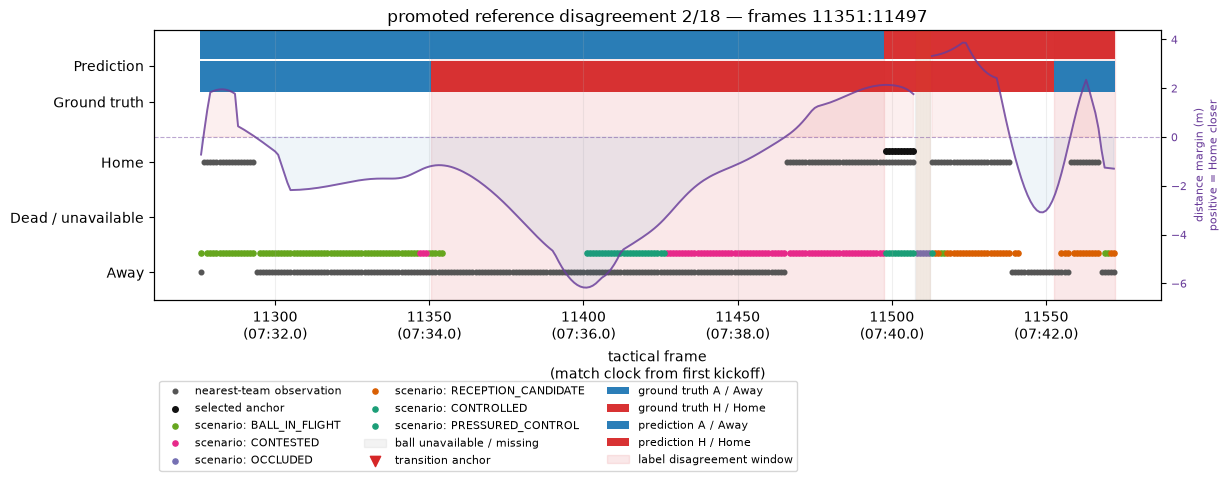

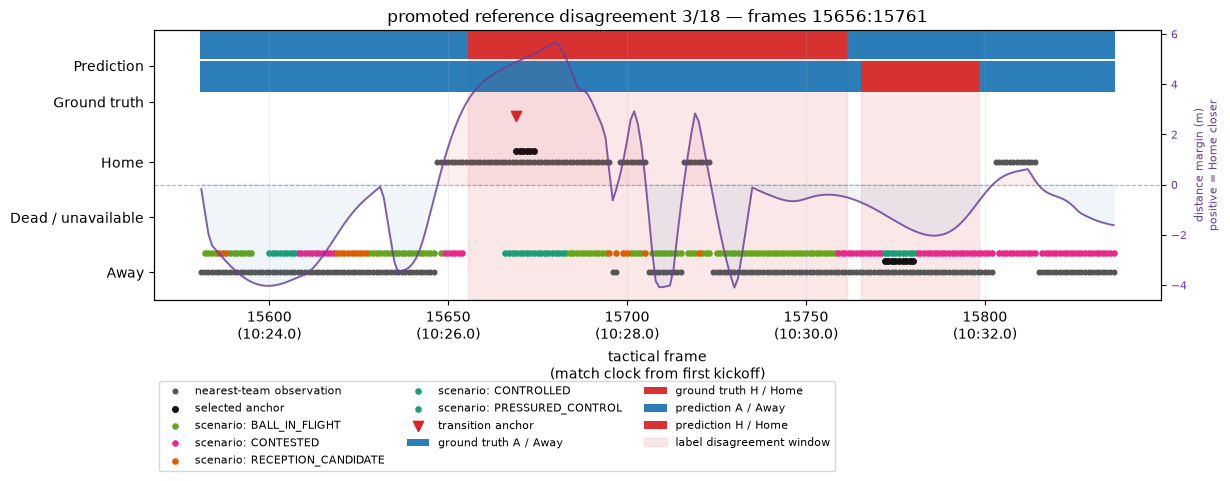

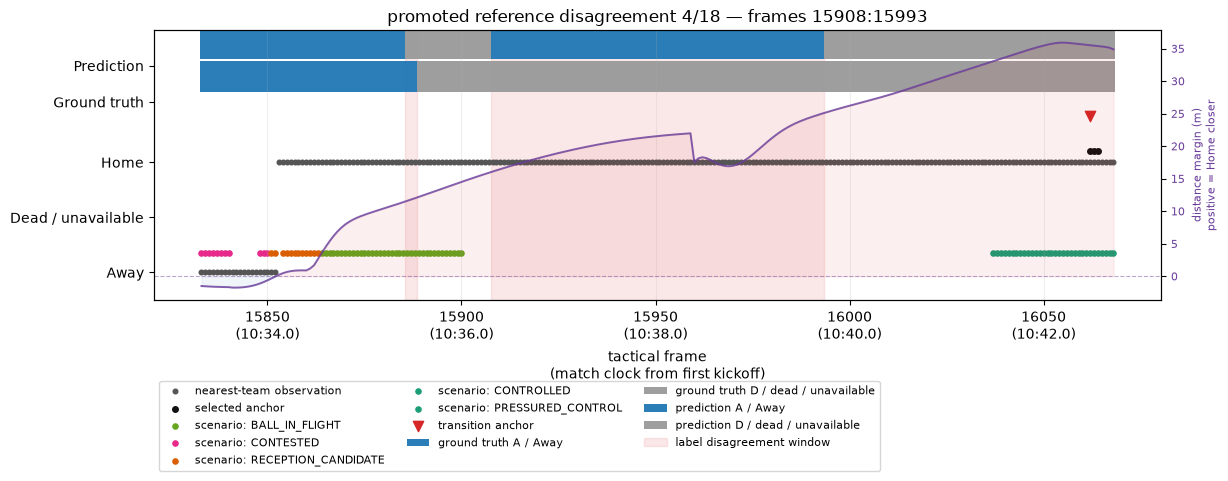

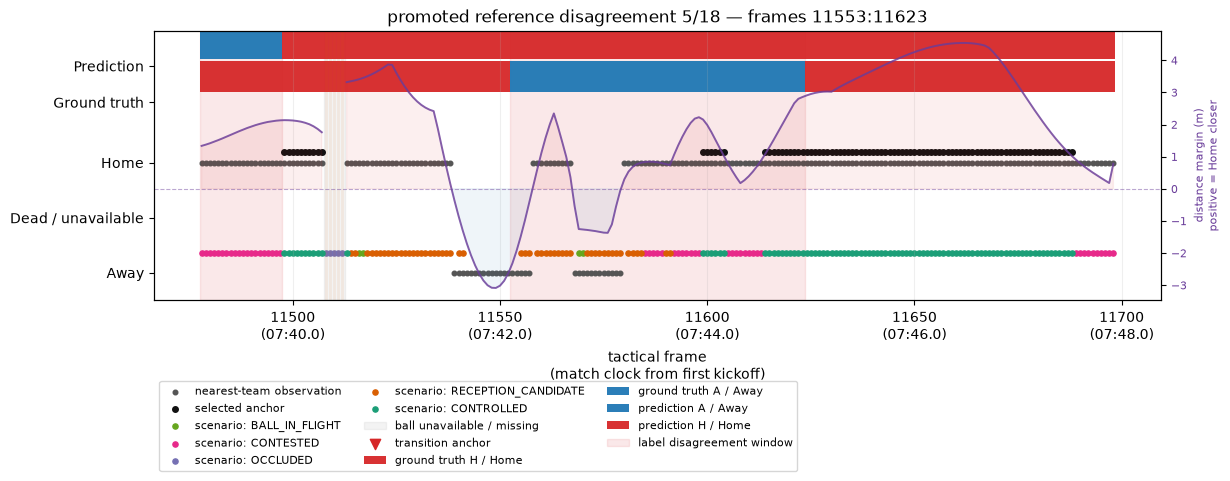

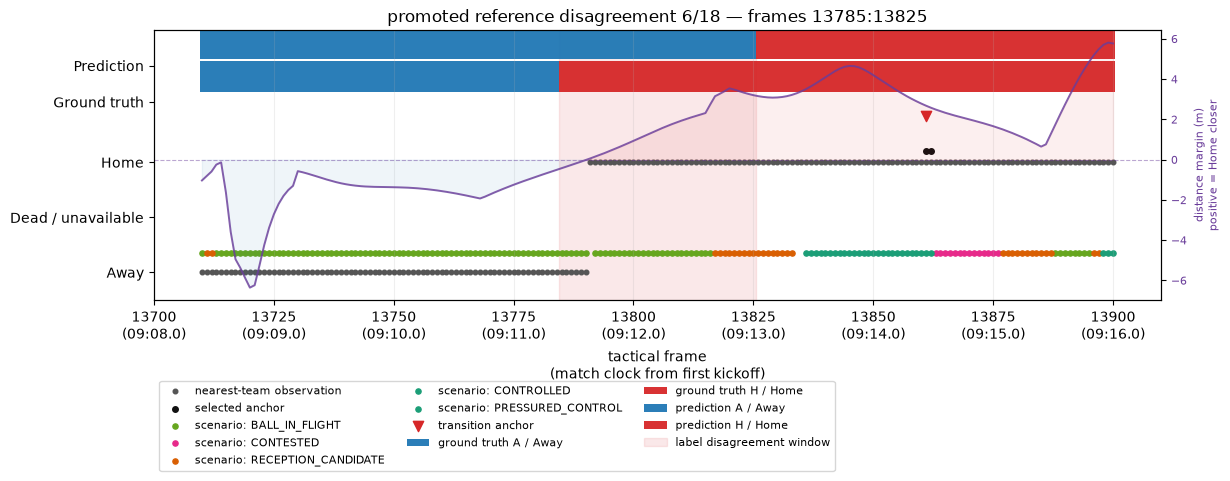

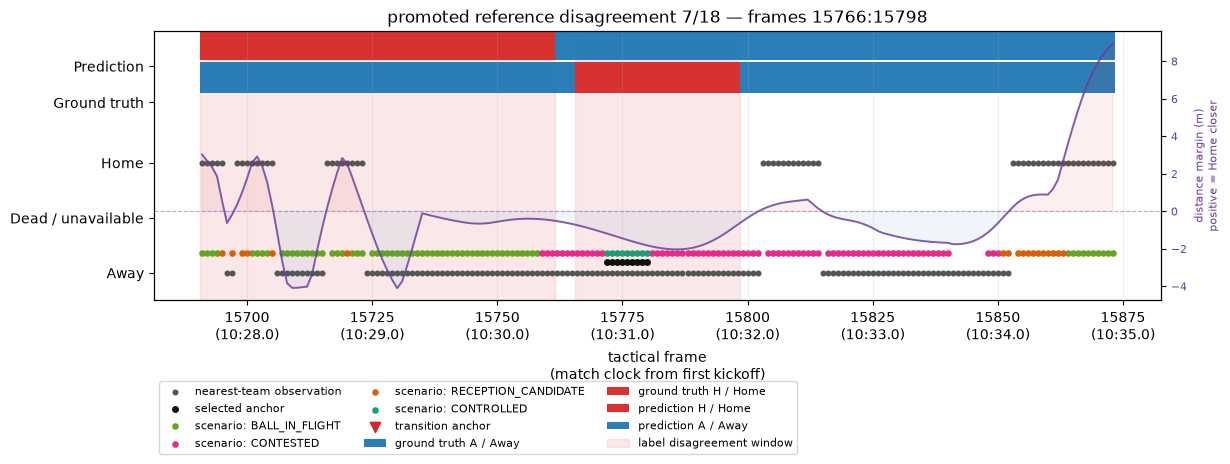

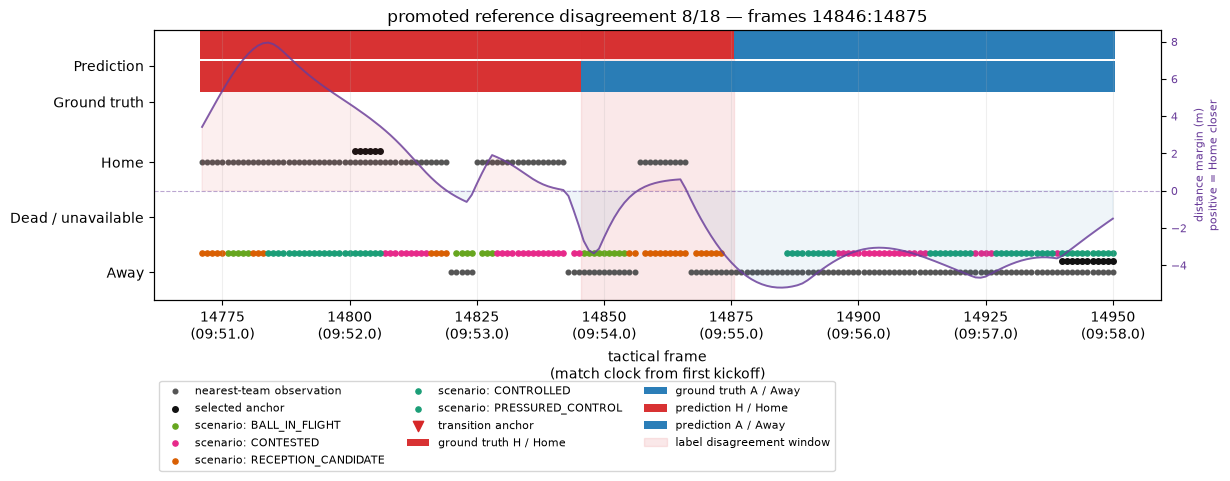

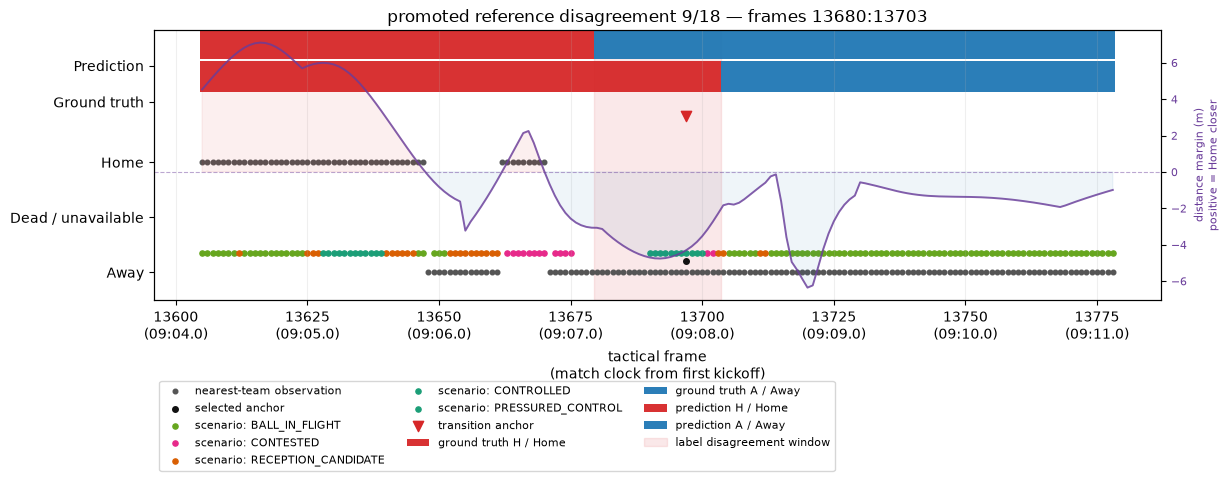

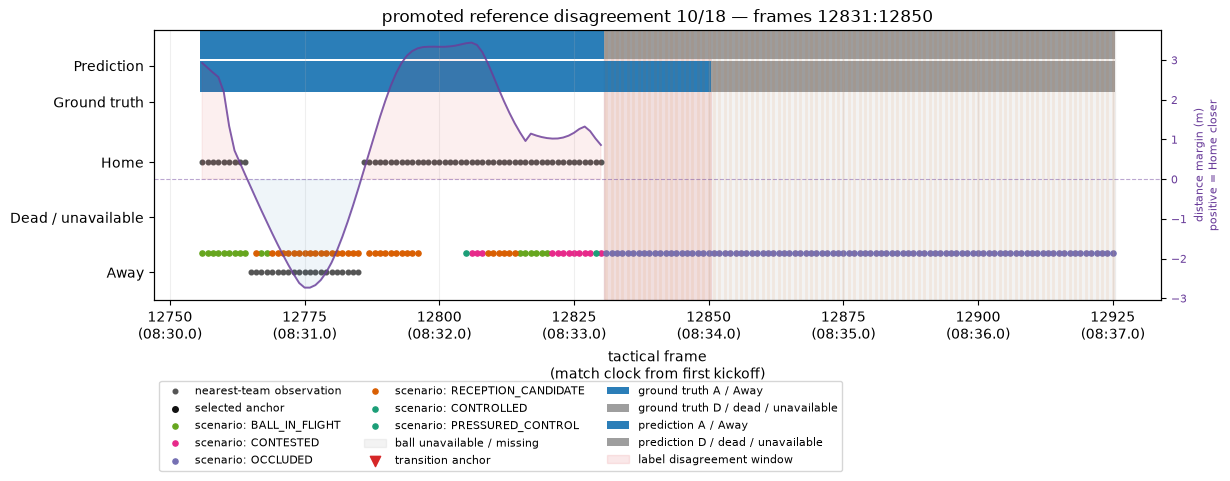

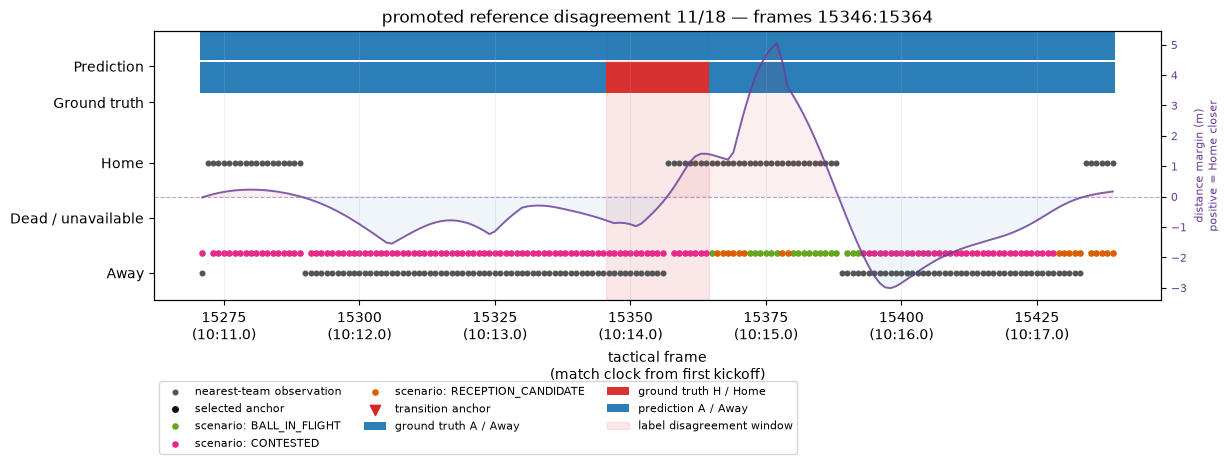

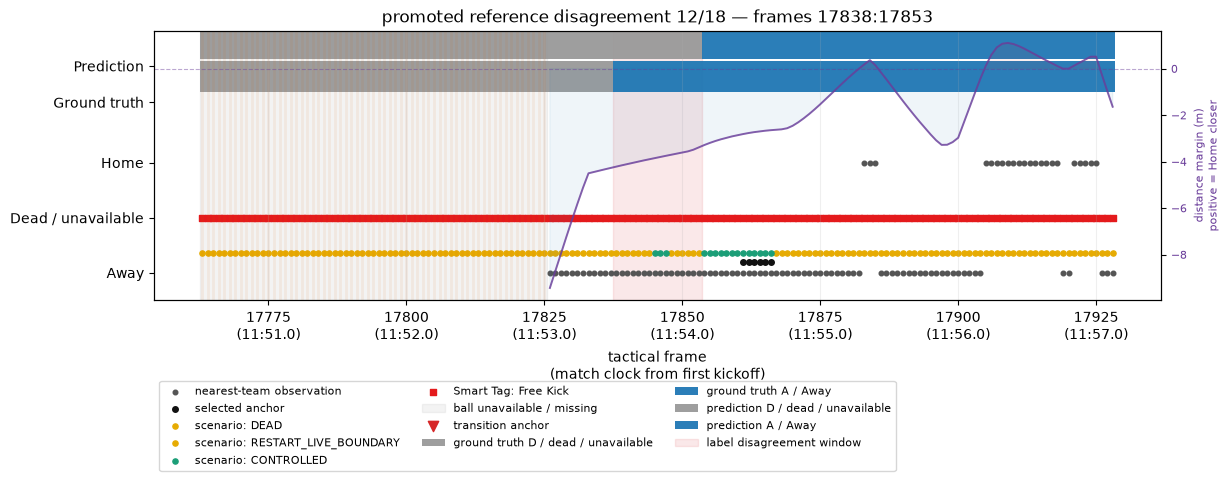

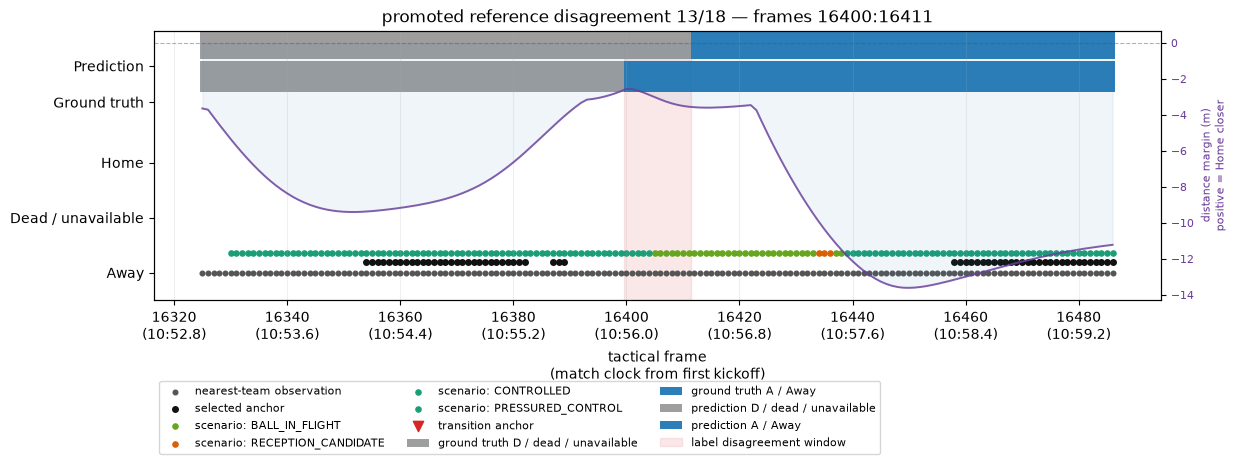

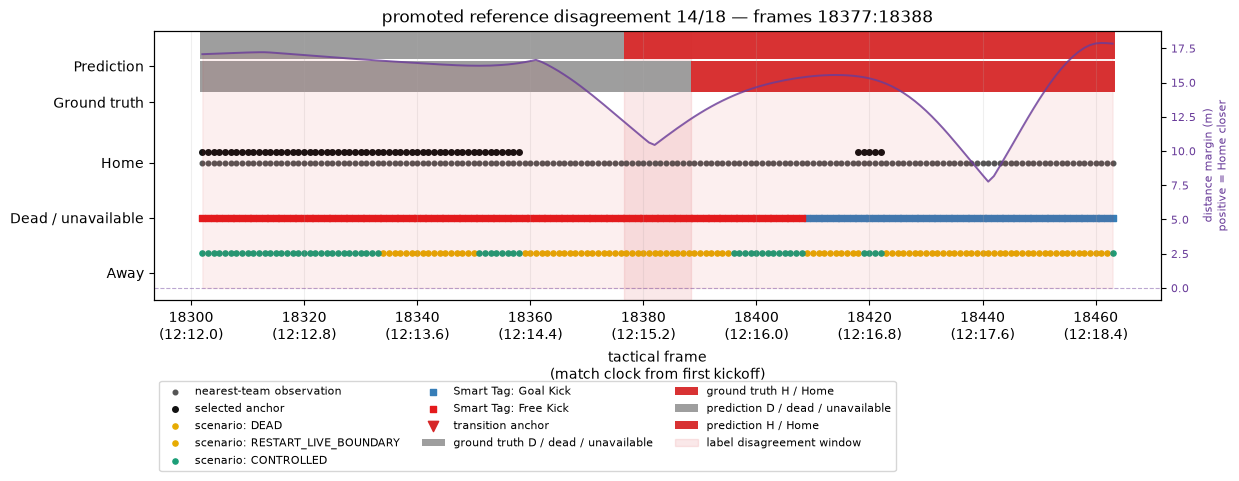

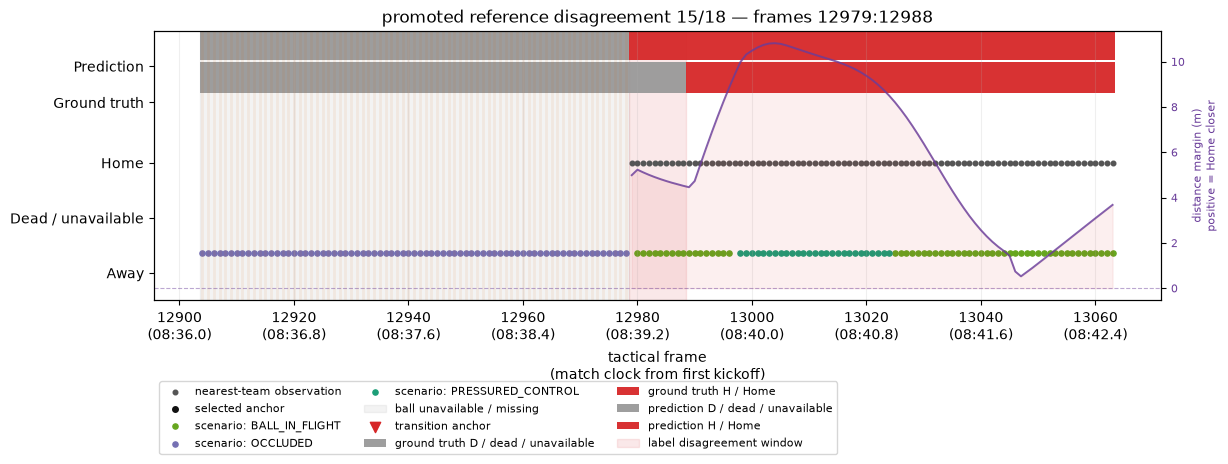

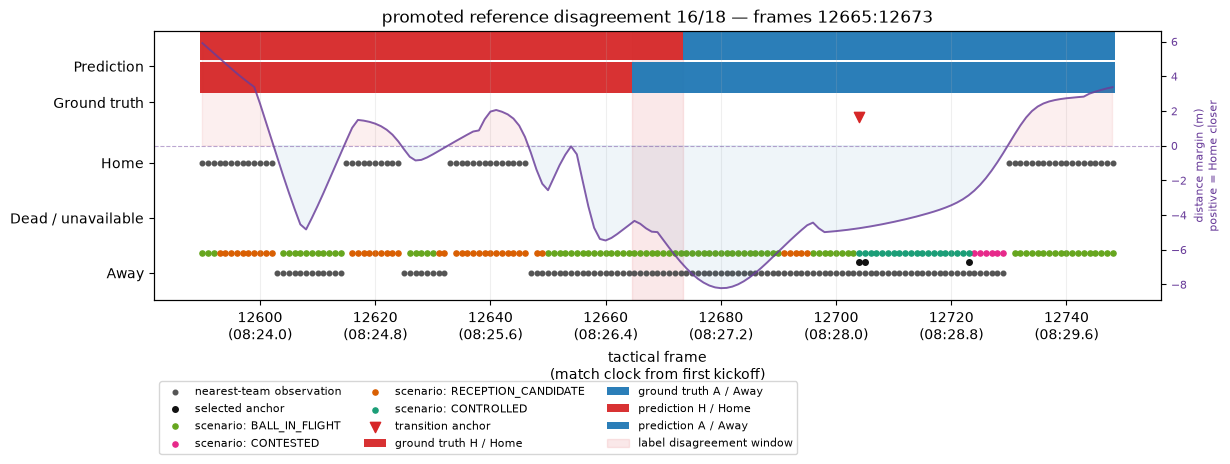

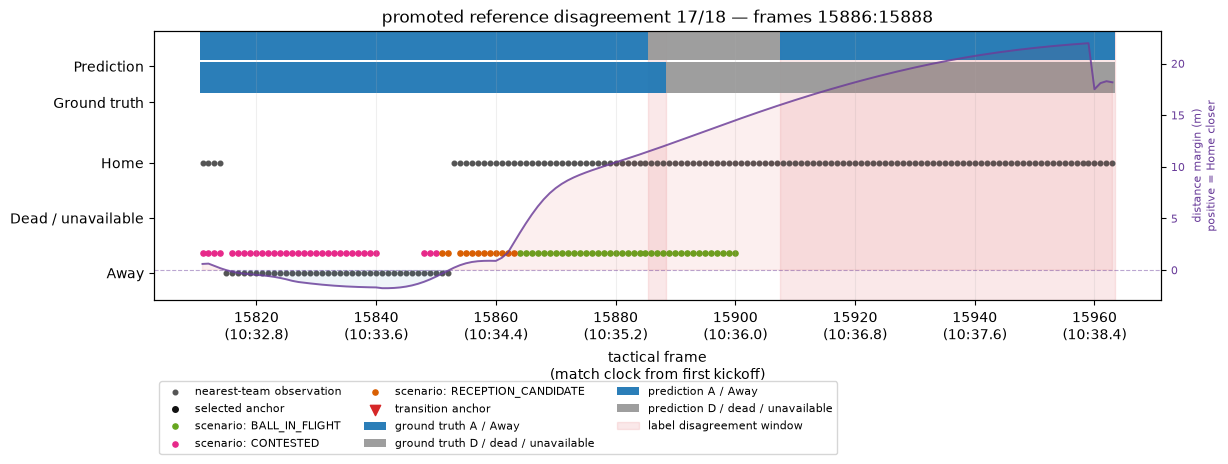

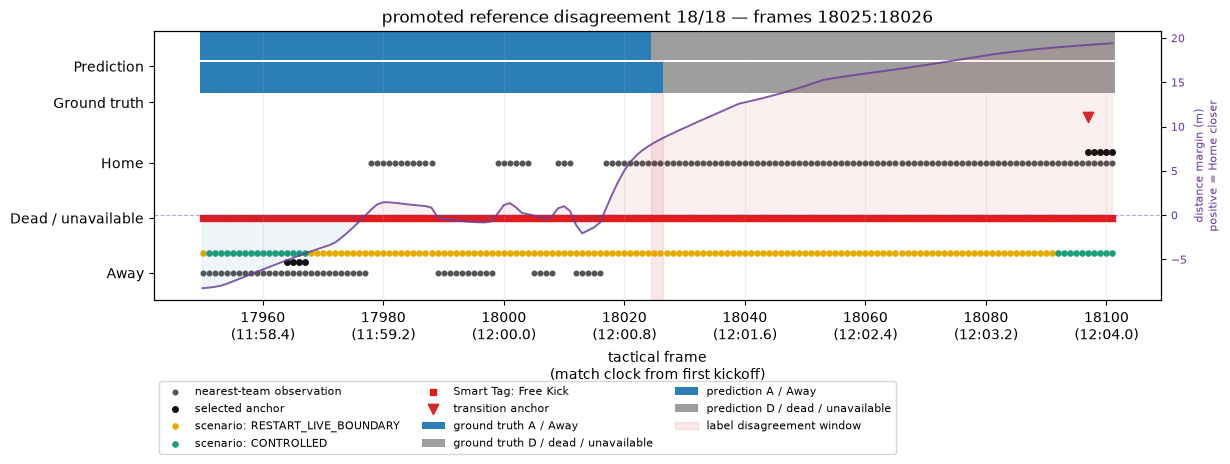

George + Kalman interaction min3: 840 wrong graded frames; 17 disagreement windows


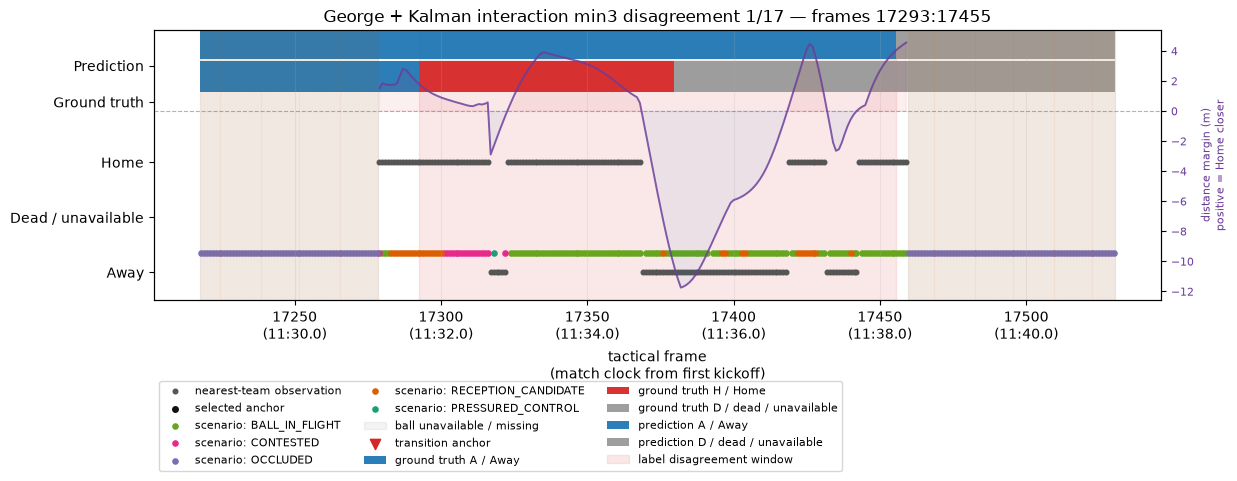

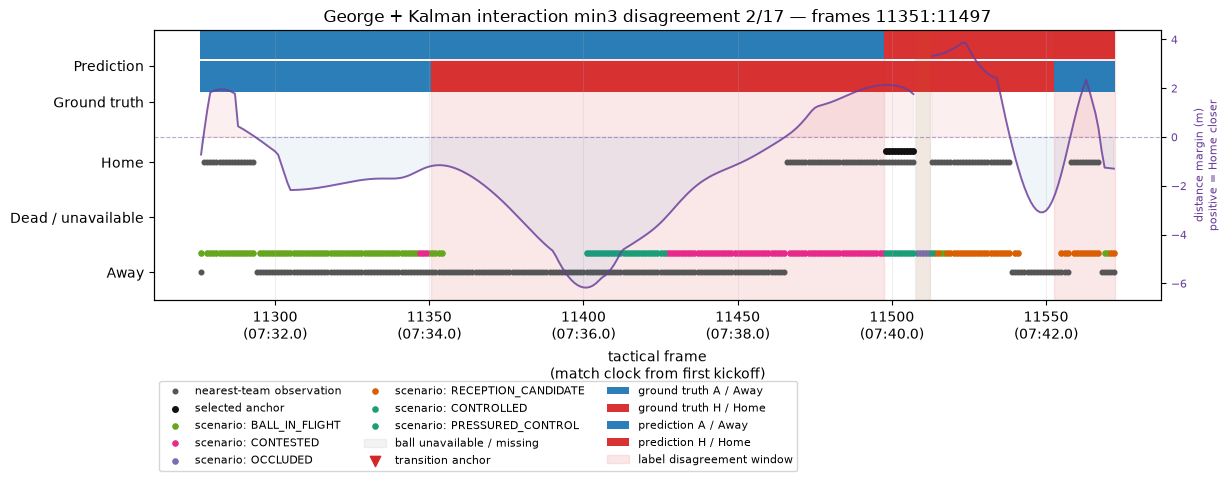

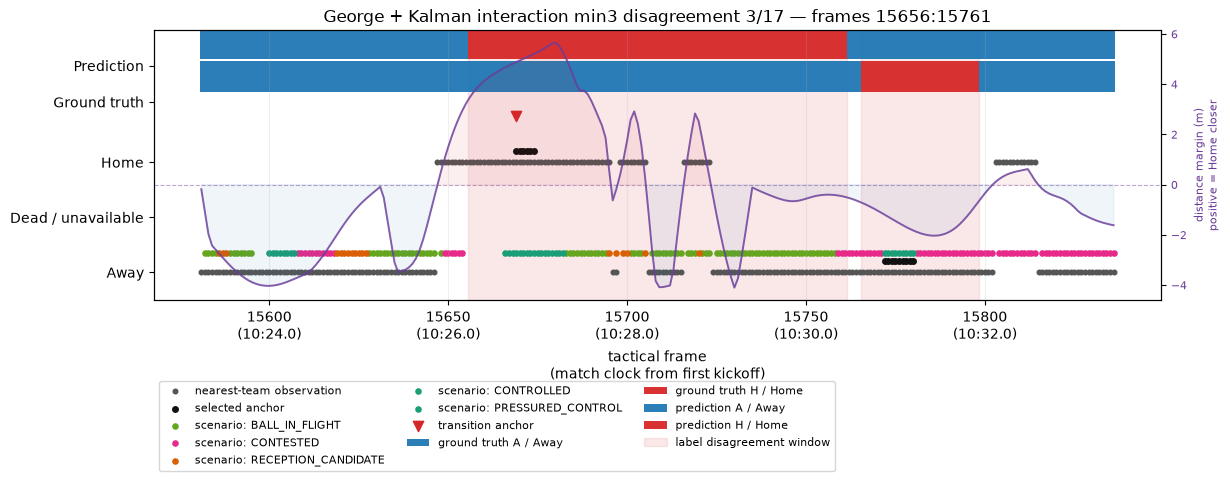

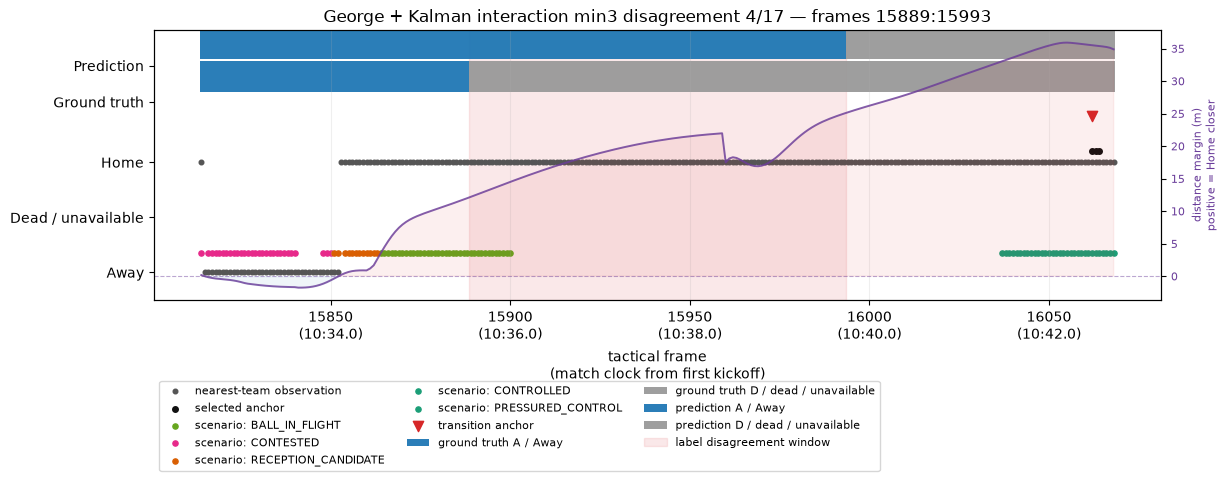

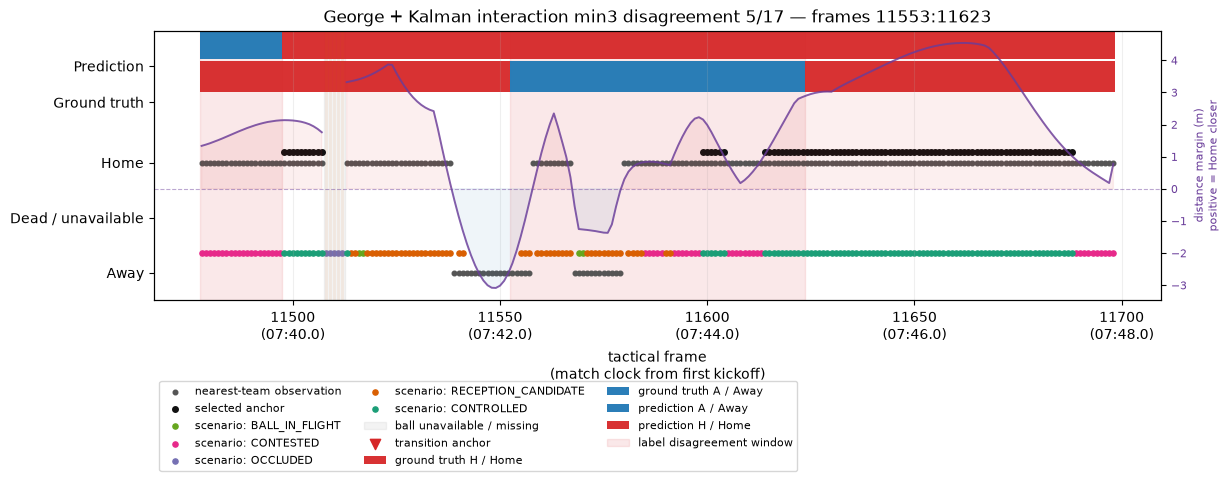

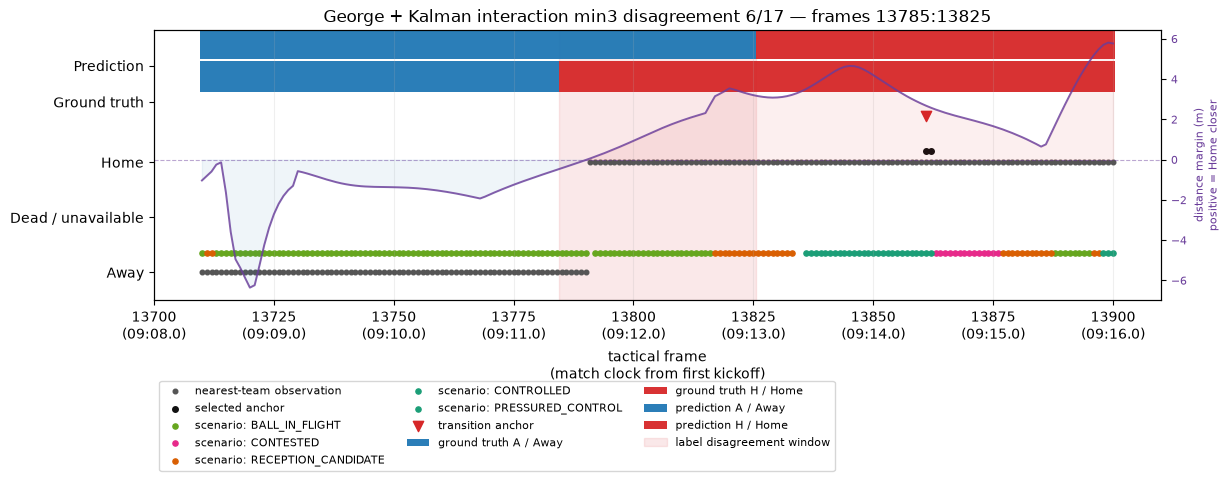

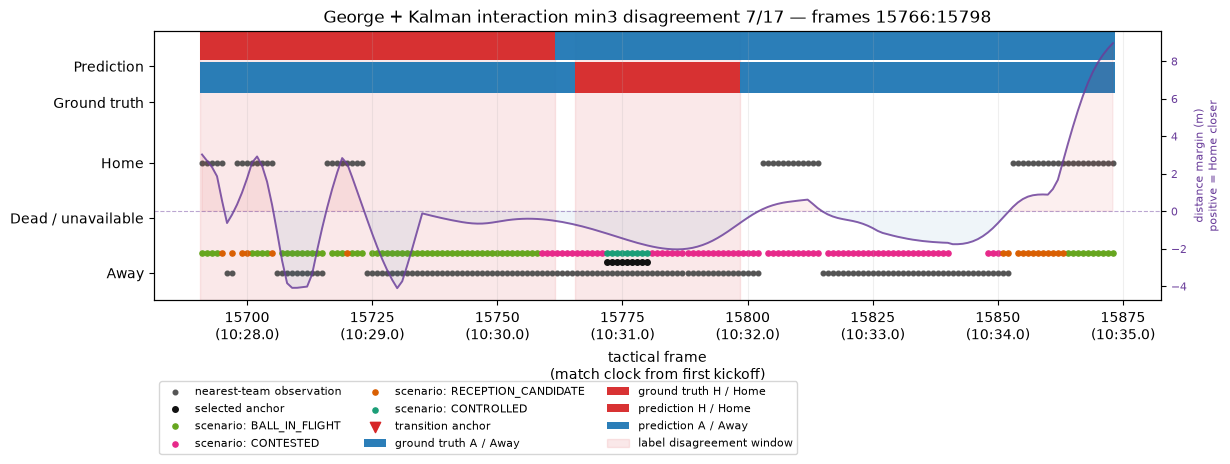

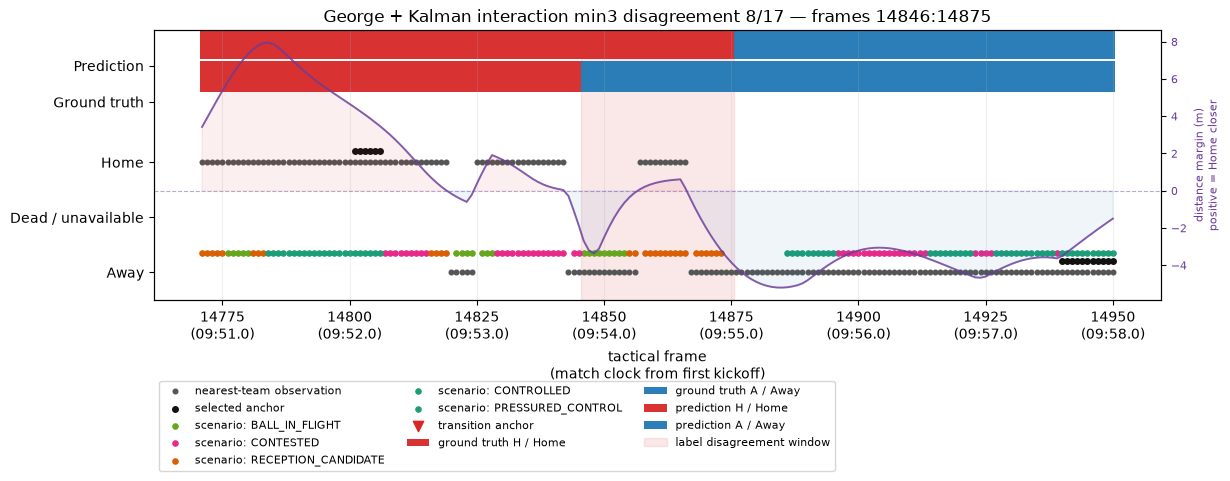

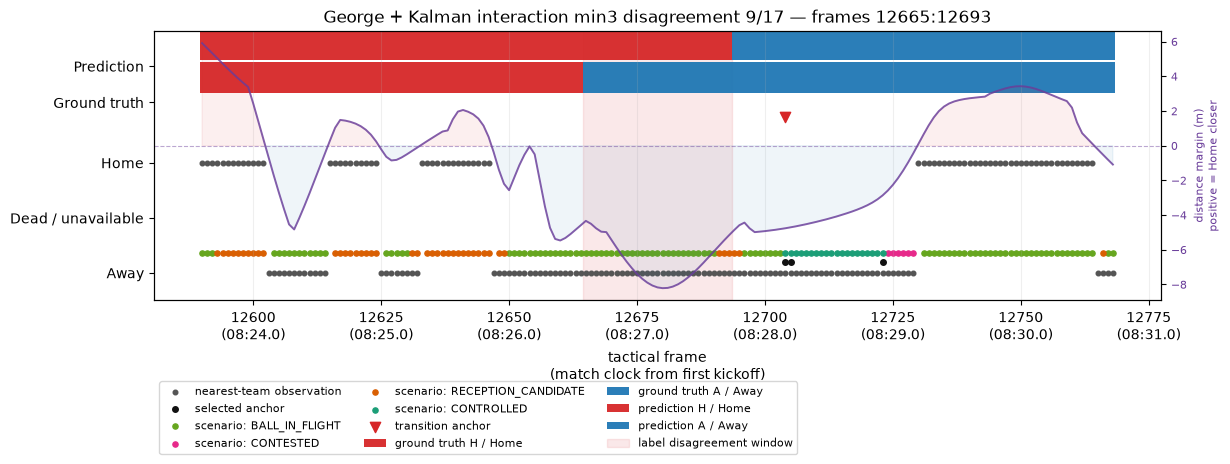

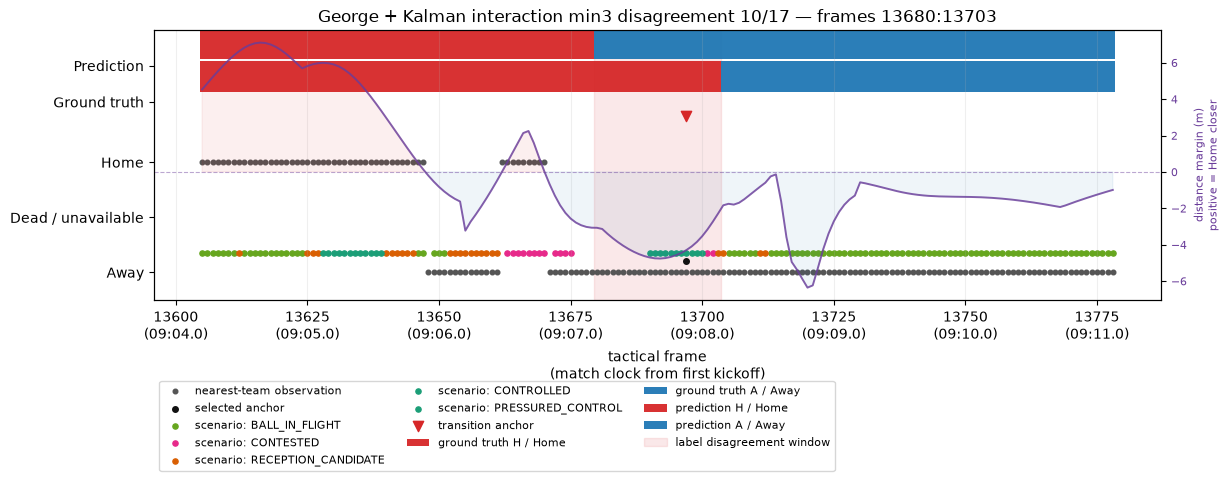

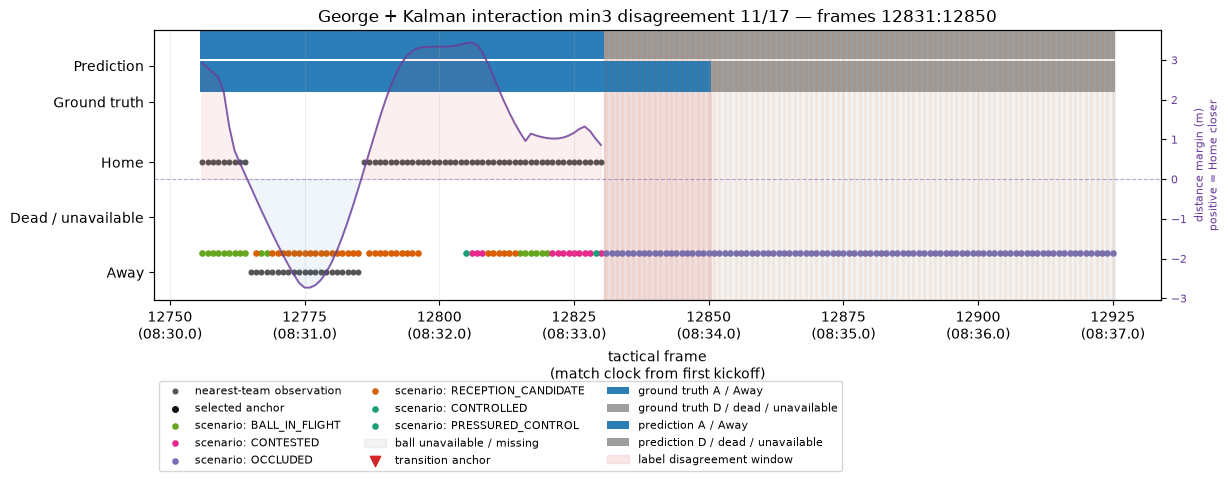

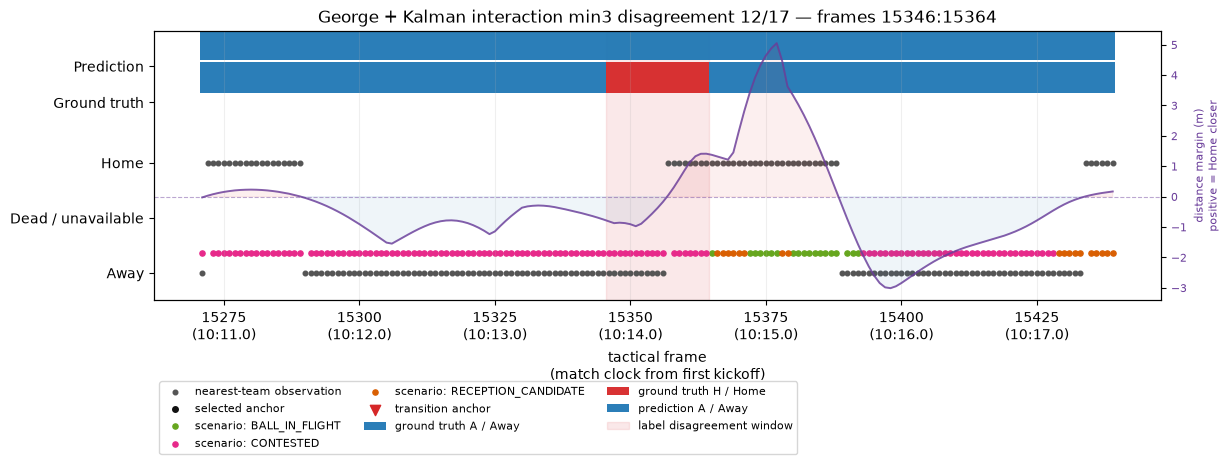

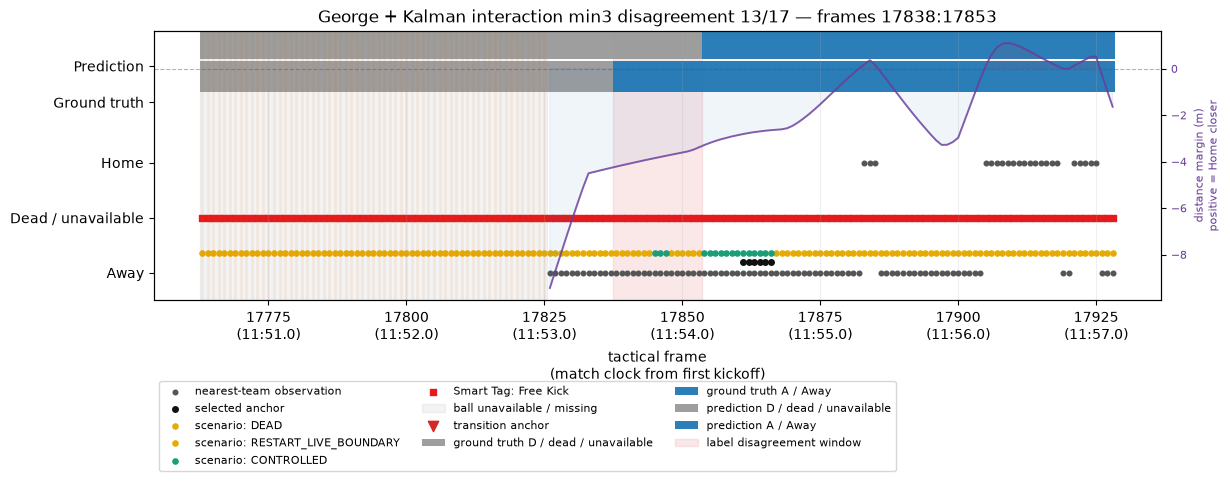

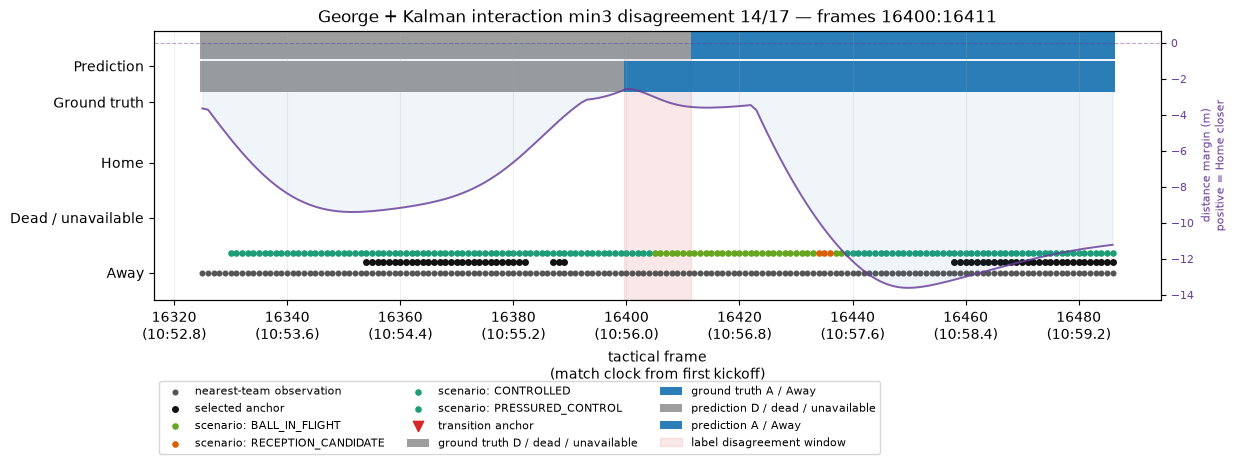

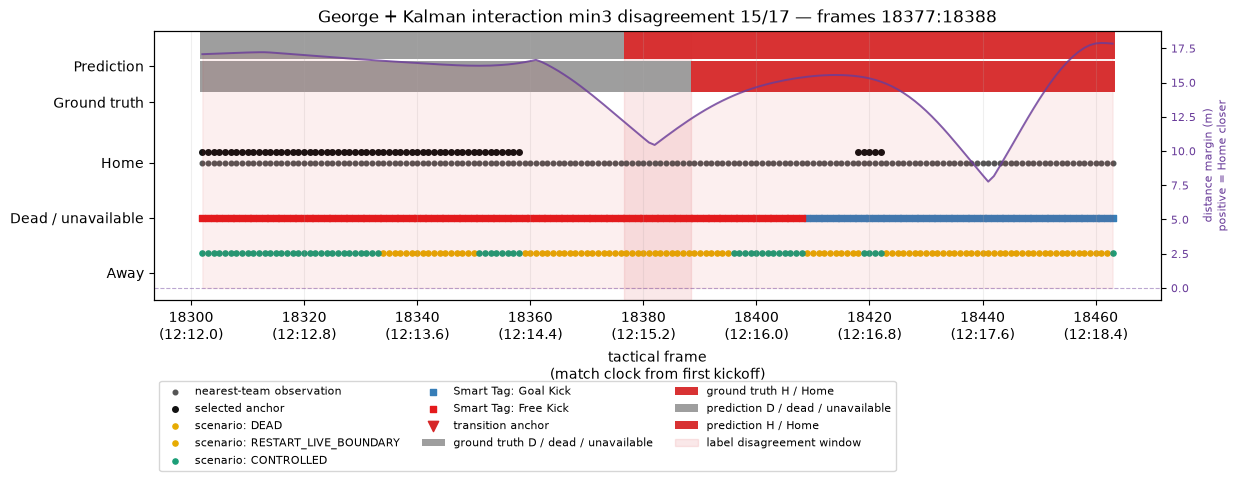

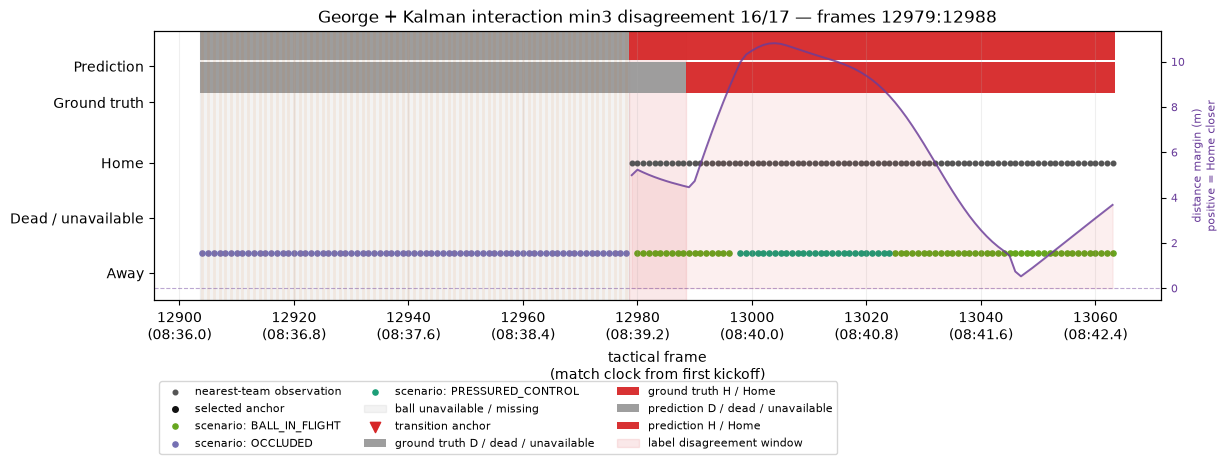

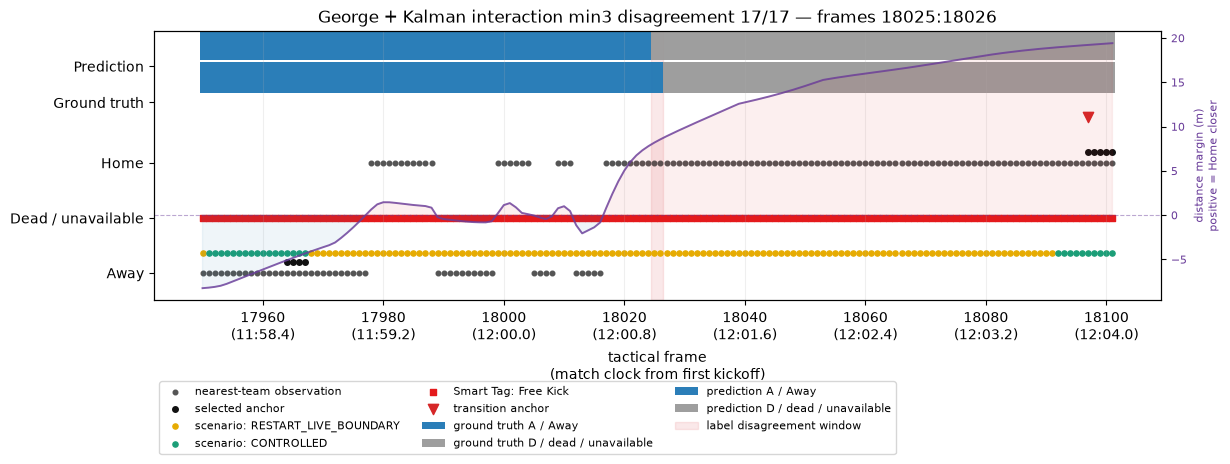

In [5]:
GEORGE_BALLFILL = ROOT / 'data' / 'ball' / 'BAR-ATH_ball.csv'
GEORGE_KALMAN_OUTPUT = ROOT / 'evaluation' / 'results' / 'diagnostic_george_interaction_attempted_pass_min3.csv'
PROMOTED_OUTPUT = ROOT / 'evaluation' / 'results' / 'diagnostic_forward_settling_dead_ball.csv'
if not GEORGE_KALMAN_OUTPUT.exists():
    raise FileNotFoundError('Run 08_run_pipeline with the George/Kalman experiment enabled first.')

george_features = build_engineered_features(
    model=ClosestTeamRuleModel(),
    rules=load_rules(),
    george_ballfill_path=GEORGE_BALLFILL if GEORGE_BALLFILL.exists() else None,
    george_evidence_only=True,
)
ground_truth = pd.read_csv(GROUND_TRUTH)
gt_by_frame = pd.Series(ground_truth['label'].astype(str).str.upper().to_numpy(), index=ground_truth['frame'].astype(int))
scoreboard = pd.read_csv(ROOT / 'evaluation' / 'scoreboard.csv')
display(scoreboard[scoreboard['submission'].astype(str).str.contains('diagnostic_visible_ball_no_switch_interval|diagnostic_george_interaction_attempted_pass_min3', regex=True)][['submission', 'macro_f1', 'spell_f1_mean', 'trans_f1_25']])

audit_candidates = {
    'promoted reference': PROMOTED_OUTPUT,
    'George + Kalman interaction min3': GEORGE_KALMAN_OUTPUT,
}
for candidate_name, candidate_path in audit_candidates.items():
    prediction = pd.read_csv(candidate_path)
    pred_by_frame = pd.Series(prediction['label'].astype(str).str.upper().to_numpy(), index=prediction['frame'].astype(int))
    graded_mismatch = (gt_by_frame != 'X') & gt_by_frame.notna() & pred_by_frame.notna() & gt_by_frame.ne(pred_by_frame)
    frames = graded_mismatch[graded_mismatch].index.to_numpy(dtype=int)
    groups = np.split(frames, np.where(np.diff(frames) > 1)[0] + 1) if len(frames) else []
    windows = sorted([(int(group[0]), int(group[-1])) for group in groups if len(group)], key=lambda pair: pair[1] - pair[0], reverse=True)
    print(f'{candidate_name}: {len(frames)} wrong graded frames; {len(windows)} disagreement windows')
    for number, (window_start, window_end) in enumerate(windows, start=1):
        left = max(int(george_features['frame'].min()), window_start - context_frames)
        right = min(int(george_features['frame'].max()), window_end + context_frames)
        figure, axis = plot_timeline_window(george_features, left, right, ground_truth=gt_by_frame, predicted_labels=pred_by_frame)
        axis.set_title(f'{candidate_name} disagreement {number}/{len(windows)} — frames {window_start}:{window_end}')
        plt.show()

## Local short-touch / flight path diagnostic

The disagreement examples expose two opposite errors: a delayed true handoff and an early false handoff. The missing operation is local, retrospective path selection—not a global threshold change.

The runner emits `diagnostic_local_touch_viterbi.csv`. It compares `H_CONTROL`, `A_CONTROL`, `H_SHORT_TOUCH`, and `A_SHORT_TOUCH` only around contact/transition activity, while protecting D/X and strong anchors. This is a diagnostic use of Viterbi: it tests whether an explicit short-touch state and bounded backtracking add a signal. It is not allowed to replace the promoted reference automatically, and public labels are used only in this notebook for evaluation.

In [6]:
LOCAL_TOUCH_OUTPUT = ROOT / 'evaluation' / 'results' / 'diagnostic_local_touch_viterbi.csv'
PROMOTED_OUTPUT = ROOT / 'evaluation' / 'results' / 'diagnostic_forward_settling_dead_ball.csv'
if not LOCAL_TOUCH_OUTPUT.exists():
    raise FileNotFoundError('Run 08_run_pipeline first; local-touch diagnostic is missing.')

scoreboard = pd.read_csv(ROOT / 'evaluation' / 'scoreboard.csv')
display(scoreboard[scoreboard['submission'].astype(str).str.contains('diagnostic_forward_settling_dead_ball|diagnostic_visible_ball_no_switch_interval|diagnostic_local_touch_viterbi', regex=True)][['submission', 'macro_f1', 'spell_f1_mean', 'trans_f1_25']])

promoted = pd.read_csv(PROMOTED_OUTPUT)
local_touch = pd.read_csv(LOCAL_TOUCH_OUTPUT)
changed = promoted.loc[promoted['label'].ne(local_touch['label']), ['frame', 'label']].copy()
changed = changed.rename(columns={'label': 'promoted_label'})
changed['local_touch_label'] = local_touch.loc[changed.index, 'label'].to_numpy()
print(f'full-length changed frames: {len(changed)}')
display(changed.head(20))

# The public examples are evaluated as windows, not used to fit the decoder.
for start, end in [(11351, 11497), (11553, 11623), (15656, 15761), (17293, 17455)]:
    mask = promoted['frame'].between(start, end)
    print(f'{start}:{end} changed frames:', int(promoted.loc[mask, 'label'].ne(local_touch.loc[mask, 'label']).sum()))

,submission,macro_f1,spell_f1_mean,trans_f1_25
0,diagnostic_forward_settling_dead_ball,0.894673,0.64000,0.486486
4,diagnostic_forward_settling_dead_ball_long_hor...,0.891747,0.62069,0.457143
5,diagnostic_forward_settling_dead_ball_strict,0.891747,0.62069,0.457143
13,diagnostic_local_touch_viterbi,0.891747,0.62069,0.457143
22,diagnostic_visible_ball_no_switch_interval,0.891747,0.62069,0.457143


full-length changed frames: 82


,frame,promoted_label,local_touch_label
15886,15886,D,A
15887,15887,D,A
15888,15888,D,A
15889,15889,D,A
15890,15890,D,A
15891,15891,D,A
15892,15892,D,A
15893,15893,D,A
15894,15894,D,A
15895,15895,D,A


11351:11497 changed frames: 0
11553:11623 changed frames: 0
15656:15761 changed frames: 0
17293:17455 changed frames: 0
